In [1]:

import pandas as pd
import tkinter as tk
from tkinter import filedialog
from pathlib import Path
from datetime import datetime
import pyarrow as pa
import pyarrow.parquet as pq

# ============================================================
# 1. DEFINIR A COLUNA DE RESPOSTAS
# ============================================================

COLUNA = (
    "B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você "
    "sentiu vontade de se machucar de propósito?"
)

# ============================================================
# 2. SELECIONAR O ARQUIVO PELO FINDER
# ============================================================

root = tk.Tk()
root.withdraw()

arquivo = filedialog.askopenfilename(
    title="Selecione a base de dados PeNSE",
    filetypes=[
        ("Arquivos Parquet", "*.parquet")
    ]
)

root.destroy()

if not arquivo:
    raise SystemExit("Nenhum arquivo foi selecionado.")

caminho = Path(arquivo)

# ============================================================
# 3. ABRIR O ARQUIVO PARQUET
# ============================================================

parquet = pq.ParquetFile(caminho)

if COLUNA not in parquet.schema_arrow.names:
    candidatas = [
        c for c in parquet.schema_arrow.names
        if "B12009" in c
    ]

    print("Colunas encontradas com B12009:", candidatas)
    raise ValueError(
        "A coluna B12009 não foi encontrada com o nome esperado."
    )

# ============================================================
# 4. DEFINIR PASTA, DATA E HORA DOS ARQUIVOS DE SAÍDA
# ============================================================

# Pasta de trabalho atual do Jupyter
pasta_saida = Path.cwd()

# Data: dia, mês abreviado em inglês
# Hora: formato de 24 horas
agora = datetime.now()
data_hora = agora.strftime("%d_%b_%H_%M_%S").lower()

saida_sim = pasta_saida / (
    f"02_PENSE2024_IDADE_13_A_17_SIM_{data_hora}.parquet"
)

saida_nao = pasta_saida / (
    f"02_PENSE2024_IDADE_13_A_17_NAO_{data_hora}.parquet"
)

# ============================================================
# 5. SEPARAR AS RESPOSTAS EM BLOCOS
# ============================================================

escritor_sim = None
escritor_nao = None

total_sim = 0
total_nao = 0
total_outros = 0

try:
    for bloco in parquet.iter_batches(batch_size=20_000):

        # Converter o bloco para DataFrame
        df_bloco = bloco.to_pandas()

        # Normalizar a representação das respostas
        respostas = (
            df_bloco[COLUNA]
            .astype("string")
            .str.strip()
        )

        # Código 3 = SIM
        # Código 1 = NÃO
        mascara_sim = respostas.isin(["3", "3.0"])
        mascara_nao = respostas.isin(["1", "1.0"])

        # Criar tabela Arrow com todas as colunas originais
        tabela = pa.Table.from_batches([bloco])

        # Inicializar os escritores no primeiro bloco
        if escritor_sim is None:
            escritor_sim = pq.ParquetWriter(
                str(saida_sim), tabela.schema
            )

            escritor_nao = pq.ParquetWriter(
                str(saida_nao), tabela.schema
            )

        # Gravar respostas SIM
        if mascara_sim.any():
            tabela_sim = tabela.filter(
                pa.array(mascara_sim.tolist())
            )
            escritor_sim.write_table(tabela_sim)
            total_sim += int(mascara_sim.sum())

        # Gravar respostas NÃO
        if mascara_nao.any():
            tabela_nao = tabela.filter(
                pa.array(mascara_nao.tolist())
            )
            escritor_nao.write_table(tabela_nao)
            total_nao += int(mascara_nao.sum())

        # Contabilizar outras respostas e ausências
        total_outros += int(
            (~mascara_sim & ~mascara_nao).sum()
        )

finally:
    if escritor_sim is not None:
        escritor_sim.close()

    if escritor_nao is not None:
        escritor_nao.close()

# ============================================================
# 6. MOSTRAR O RESUMO FINAL
# ============================================================

print("=" * 55)
print("SEPARAÇÃO CONCLUÍDA")
print("=" * 55)

print(f"Arquivo original: {caminho}")
print(f"Total de registros: {parquet.metadata.num_rows:,}")
print(f"Respondeu SIM (3): {total_sim:,}")
print(f"Respondeu NÃO (1): {total_nao:,}")
print(f"Outras respostas/ausências: {total_outros:,}")

print("\nArquivos gerados:")

print(f"\nSIM:\n{saida_sim}")
print(f"\nNÃO:\n{saida_nao}")

print("\nPasta de saída:")
print(pasta_saida)

SEPARAÇÃO CONCLUÍDA
Arquivo original: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/07_PENSE2024_IDADE_13_A_17.parquet
Total de registros: 118,041
Respondeu SIM (3): 38,561
Respondeu NÃO (1): 78,789
Outras respostas/ausências: 691

Arquivos gerados:

SIM:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/03_Divisao_base_dados_duas_intencao_sim_nao/02_PENSE2024_IDADE_13_A_17_SIM_18_oct_15_26_54.parquet

NÃO:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/03_Divisao_base_dados_duas_intencao_sim_nao/02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet

Pasta de saída:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/03_Divisao_base_dados_duas_intencao_sim_nao


ARQUIVO DE CODIFICAÇÃO
Arquivo: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/01_Colunas_recomendadas_pense_2024_final.xlsx
Dimensões: (41, 15)


,Nº,Dimensão,Código da coluna,Descrição da variável,Prioridade,Uso recomendado,Nível,Justificativa,Cuidados metodológicos,Tipo,Categorias/codificação,Observações do dicionário,Nova numeracao,Nova codificacao,Percentagem nulos
0,0,Desfecho,B12009,"NOS ÚLTIMOS 12 MESES, alguma vez você sentiu v...",Target,Usar como variável-alvo (Y),Aluno,Indicador direto de vulnerabilidade para autol...,Não usar como preditora.,Num,1 - Sim\n2 - Não\n-2 - Abandono\n-9 - Sem resp...,NaN,"1=3,2=1,-9/-2/-1=0",3=Sim\n1=Nao\n0=Sem resposta,0.005758
1,1,Ambiente escolar e fatores potencialmente prot...,E01P117,"NOS ÚLTIMOS 12 MESES, a escola contou com algu...",Contexto escolar,Usar em modelo multinível/alternativo,Escola,Mede suporte psicológico e ações escolares de ...,Exige chave de vinculação aluno-escola; pode h...,Num,"1 - Sim, para alunos, professores e funcionári...","1 - Sim, para alunos, professores e funcionári...","1=1,2=2,3=3,4=4,-9/-2/-1=0","1=Sim, para alunos, professores e funcionários...",0.001222
2,2,Ambiente escolar e fatores potencialmente prot...,E01P11801,Quais tipos de suporte a escola oferece? - A e...,Contexto escolar,Usar em modelo multinível/alternativo,Escola,Mede suporte psicológico e ações escolares de ...,Exige chave de vinculação aluno-escola; pode h...,Num,0 - Não\n1 - Sim\n-1 - Pulo\n-9 - Sem resposta,1 - Sim (3) 0 - Nao (1) ...,"1=3,0=1,-9/-2/-1=0)",3=Sim\n1=Nao\n0=Sem resposta,0.184812
3,3,Ambiente escolar e fatores potencialmente prot...,E01P11802,Quais tipos de suporte a escola oferece? - A e...,Contexto escolar,Usar em modelo multinível/alternativo,Escola,Mede suporte psicológico e ações escolares de ...,Exige chave de vinculação aluno-escola; pode h...,Num,0 - Não\n1 - Sim\n-1 - Pulo\n-9 - Sem resposta,1 - Sim (3) 0 - Nao (1) ...,"1=3,0=1,-9/-2/-1=0)",3=Sim\n1=Nao\n0=Sem resposta,0.184812
4,4,Ambiente escolar e fatores potencialmente prot...,E01P8505,"NOS ÚLTIMOS 12 MESES, a escola desenvolveu qua...",Contexto escolar,Usar em modelo multinível/alternativo,Escola,Mede suporte psicológico e ações escolares de ...,Exige chave de vinculação aluno-escola; pode h...,Num,0 - Não\n1 - Sim\n-9 - Sem resposta,1 - Sim (3) 0 - Nao (1) ...,"1=3,0=1,-9/-2/-1=0)",3=Sim\n1=Nao\n0=Sem resposta,0.003951



ARQUIVOS SELECIONADOS
1. 02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet
2. 02_PENSE2024_IDADE_13_A_17_SIM_18_oct_15_26_54.parquet

Lendo: 02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet
Base identificada como: NAO
Dimensões: 78,789 linhas × 41 colunas

Lendo: 02_PENSE2024_IDADE_13_A_17_SIM_18_oct_15_26_54.parquet
Base identificada como: SIM
Dimensões: 38,561 linhas × 41 colunas

COMPARAÇÃO GERAL DAS BASES


,Base,Linhas,Colunas,Memória (MB),Valores ausentes,Linhas duplicadas,Variáveis numéricas,Variáveis categóricas
0,SIM,38561,41,13.57,0,0,41,0
1,NAO,78789,41,27.73,0,161,41,0



##########################################################################################
INSPEÇÃO DA BASE: NAO
##########################################################################################

1. Dimensões
Linhas: 78,789
Colunas: 41

2. Memória utilizada
27.73 MB

3. Primeiras linhas


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
0,1,11,0,1,2,4,3,1,3,3,...,1,1,1,1,1,3,1,1,3,1
1,1,11,0,1,2,1,3,1,1,3,...,1,3,3,1,1,1,3,4,0,0
2,1,11,0,2,2,2,3,3,3,3,...,1,1,1,1,1,1,3,4,0,0
3,1,11,0,2,2,4,3,3,3,3,...,1,1,1,1,1,1,3,4,0,0
4,1,11,0,1,2,4,3,1,1,3,...,1,1,1,1,1,1,3,4,0,0


... (28 outputs left out)


11. Número de linhas duplicadas
0

12. Variáveis constantes


,Variáveis constantes
0,"B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você..."



COMPARAÇÃO DE FREQUÊNCIAS: SIM × NAO
Variáveis comuns: 41

--------------------------------------------------------------------------------
VARIÁVEL: REGIAO - código de regiões
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
nordeste,12724,32.99707,26298,33.377756
norte,9920,25.725474,18568,23.566742
sudeste,6779,17.579938,14999,19.036921
centro-oeste,4966,12.878297,9864,12.519514
sul,4172,10.819221,9060,11.499067


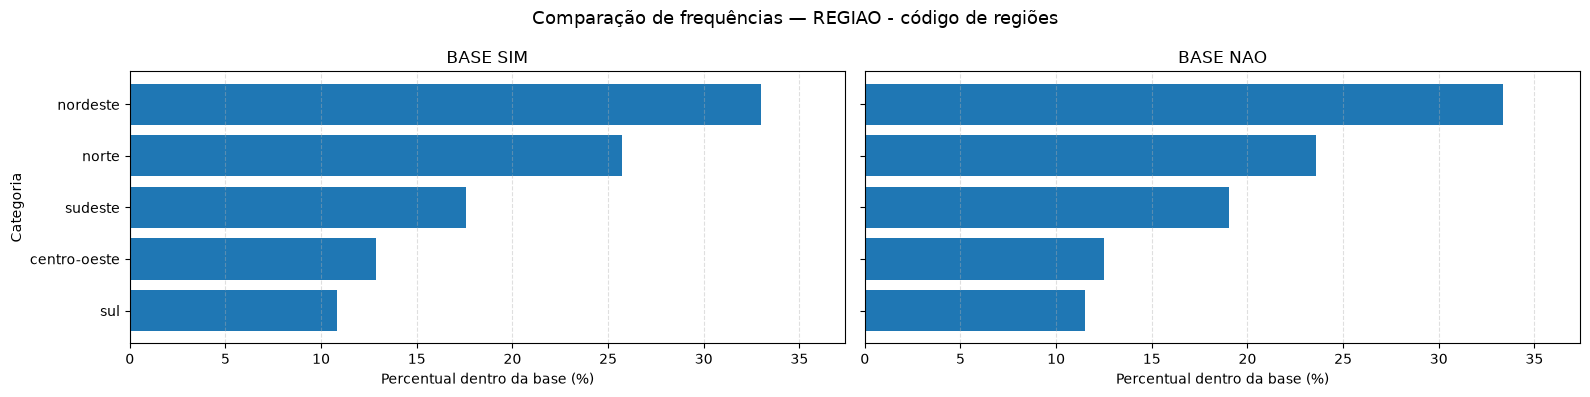


--------------------------------------------------------------------------------
VARIÁVEL: UF - código UF
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Espírito Santo,1787,4.634216,4135,5.248195
Pernambuco,1766,4.579757,3598,4.566627
São Paulo,1761,4.56679,3900,4.94993
Bahia,1726,4.476025,3638,4.617396
Rio de Janeiro,1713,4.442312,3577,4.539974
Amazonas,1576,4.087031,2681,3.402759
Tocantins,1566,4.061098,3160,4.010712
Mato Grosso do Sul,1539,3.991079,2941,3.732755
Rondônia,1535,3.980706,3236,4.107172


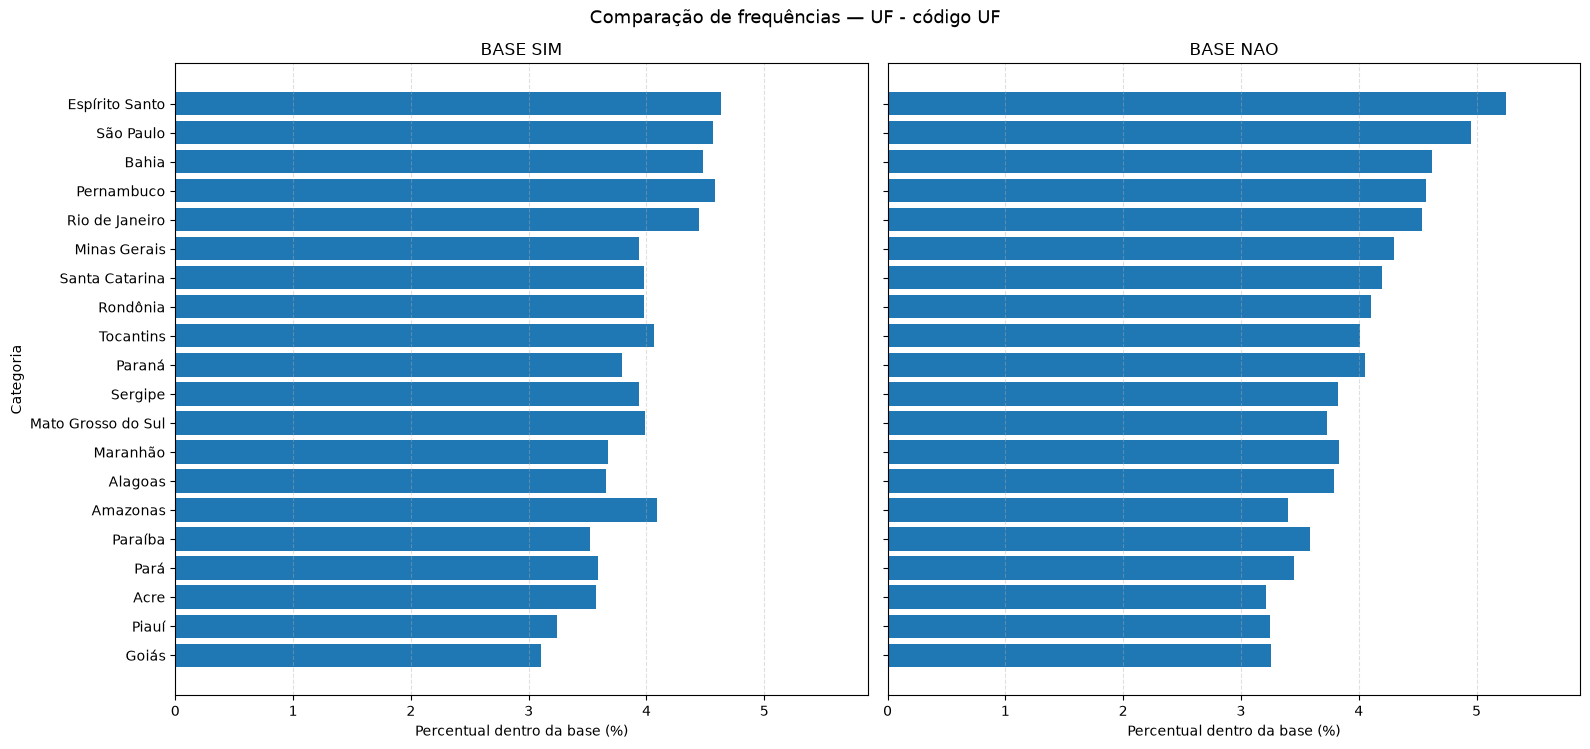


--------------------------------------------------------------------------------
VARIÁVEL: CAPITAL - indica se é município da capital
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Capital,20452,53.038044,40284,51.128965
0,18109,46.961956,38505,48.871035


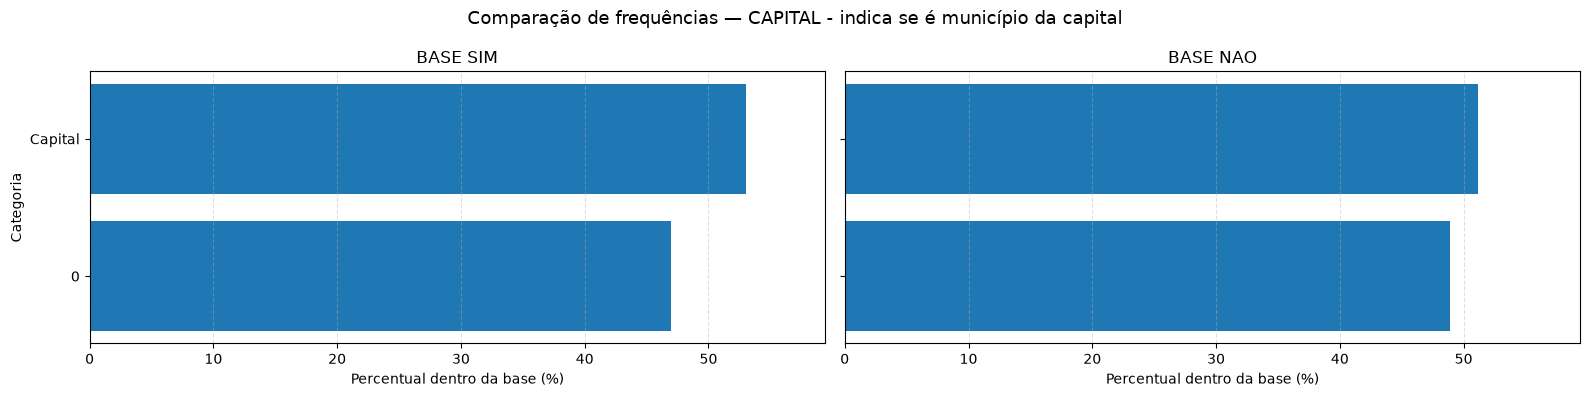


--------------------------------------------------------------------------------
VARIÁVEL: B01001A - Qual é o seu sexo?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Mulher,25762,66.808433,33198,42.135323
Homem,12799,33.191567,45591,57.864677


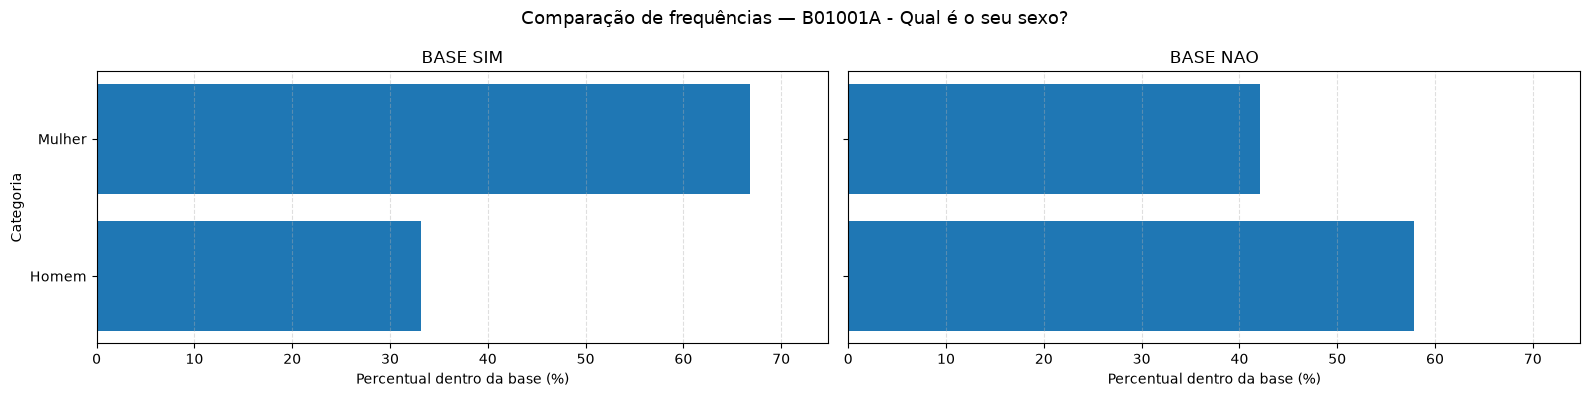


--------------------------------------------------------------------------------
VARIÁVEL: IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
13 a 15 anos,25528,66.201603,50773,64.441737
16 e 17 anos,13033,33.798397,28016,35.558263


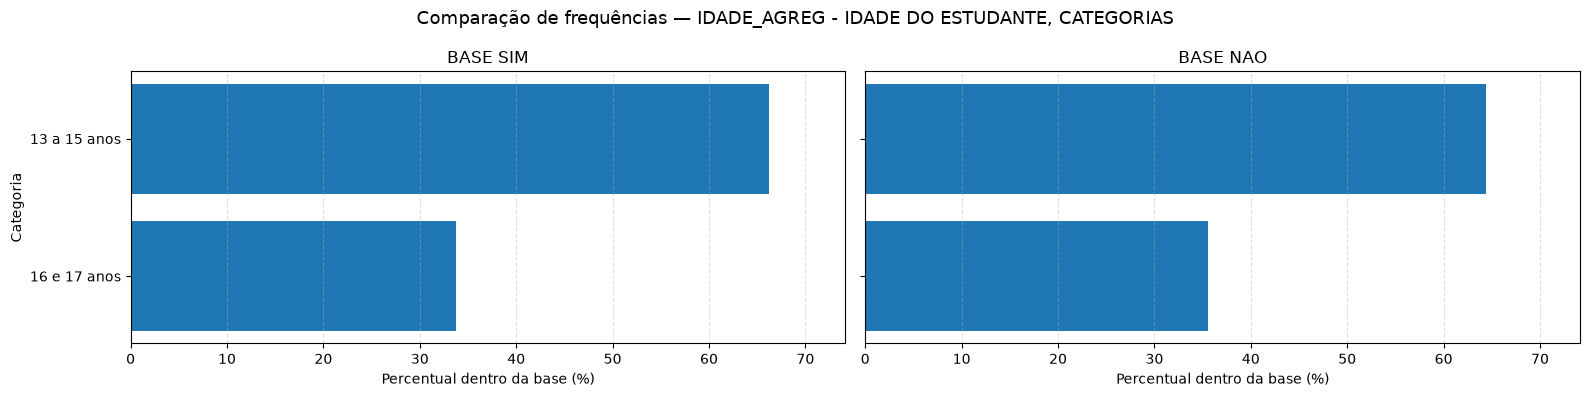


--------------------------------------------------------------------------------
VARIÁVEL: B01002 - Qual é a sua cor ou raça?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Parda,16663,43.212054,33708,42.782622
Branca,15498,40.190866,32701,41.504525
Preta,4147,10.754389,8459,10.73627
Amarela,1170,3.034154,2009,2.549848
Indígena,892,2.313218,1596,2.025663
Sem reposta,191,0.495319,316,0.401071


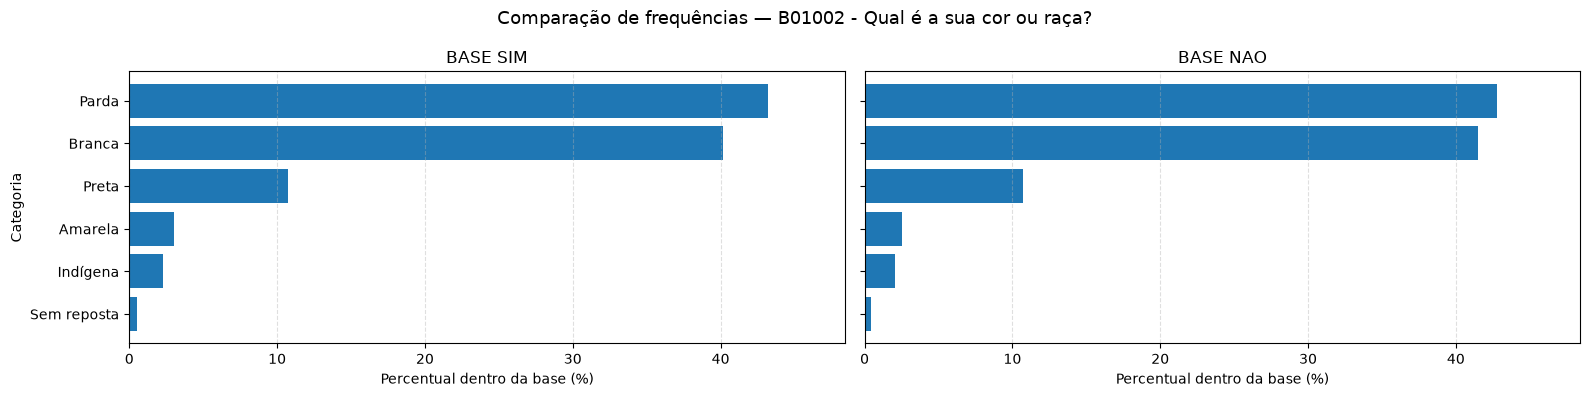


--------------------------------------------------------------------------------
VARIÁVEL: B01006 - Você mora com sua mãe?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,33882,87.865979,71543,90.803285
Nao,4670,12.110682,7229,9.175139
Sem resposta,9,0.02334,17,0.021577


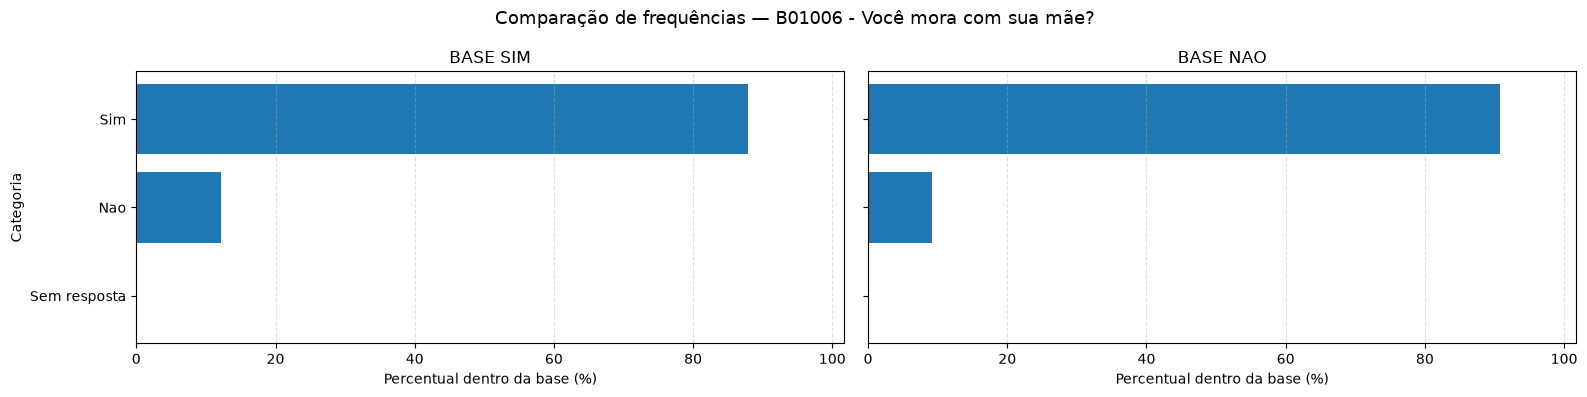


--------------------------------------------------------------------------------
VARIÁVEL: B01007 - Você mora com seu pai?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,22296,57.820077,51674,65.585297
Nao,16243,42.12287,27072,34.360126
Sem resposta,22,0.057052,43,0.054576


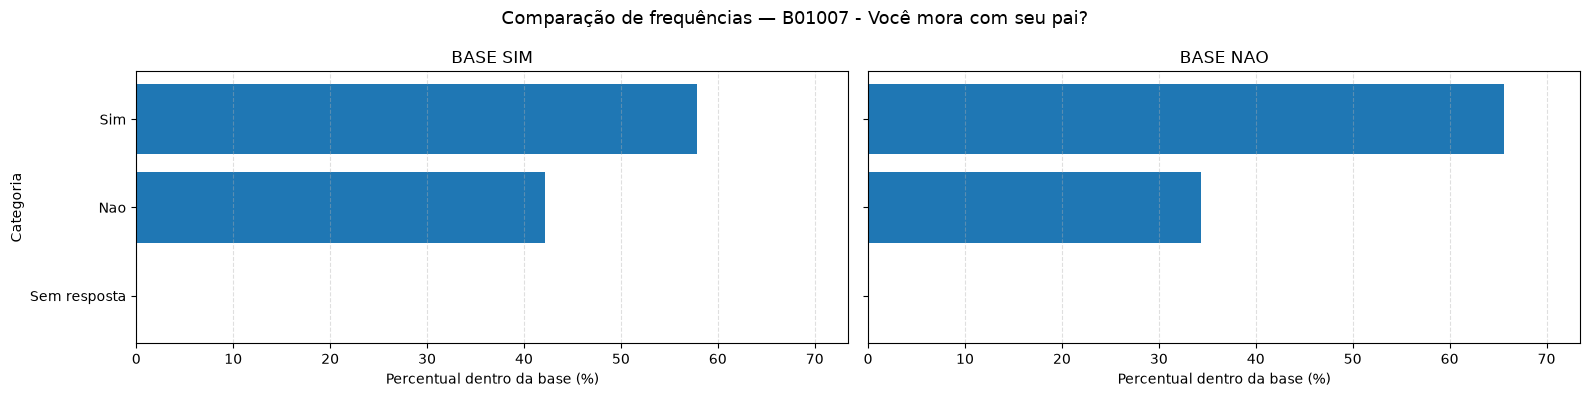


--------------------------------------------------------------------------------
VARIÁVEL: B01015B - Na sua casa tem computador ou notebook?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,23960,62.135318,50776,64.445544
Nao,14588,37.830969,27982,35.51511
Sem resposta,13,0.033713,31,0.039346


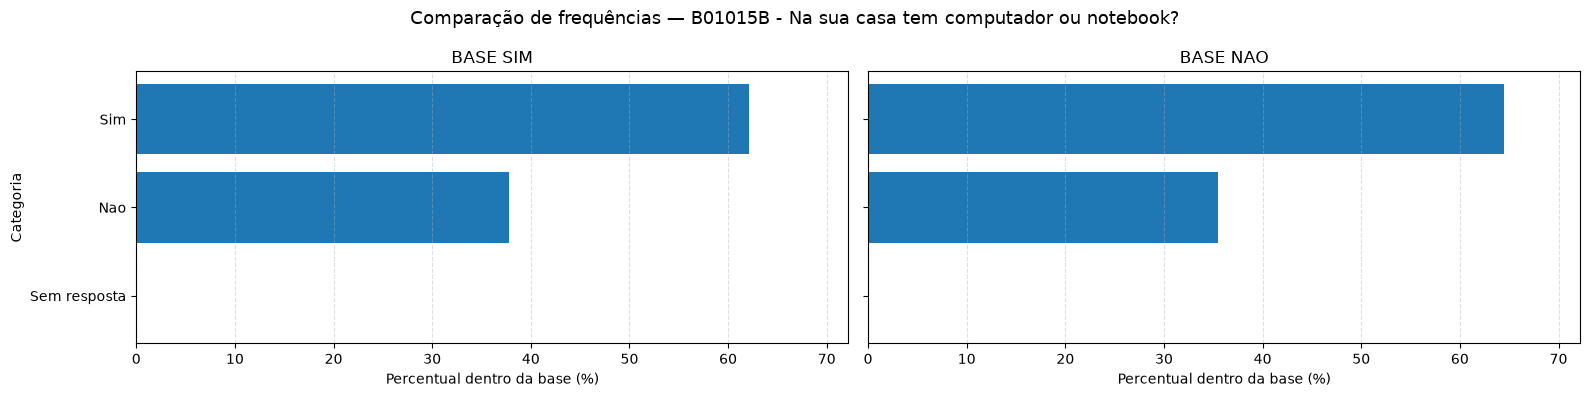


--------------------------------------------------------------------------------
VARIÁVEL: B01016 - Você tem acesso à internet em sua casa?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,37450,97.118851,76899,97.601188
Nao,1106,2.868183,1874,2.378505
Sem resposta,5,0.012966,16,0.020307


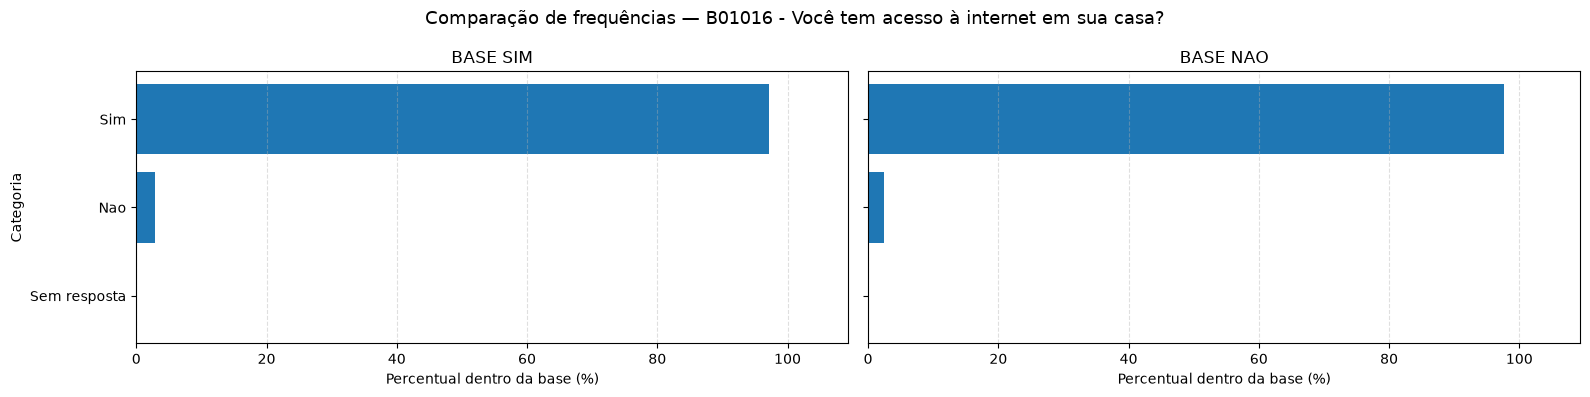


--------------------------------------------------------------------------------
VARIÁVEL: B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Um ou mais dias,25149,65.218744,57266,72.682735
Nenhum dia,13369,34.669744,21392,27.150998
Sem resposta,43,0.111512,131,0.166267


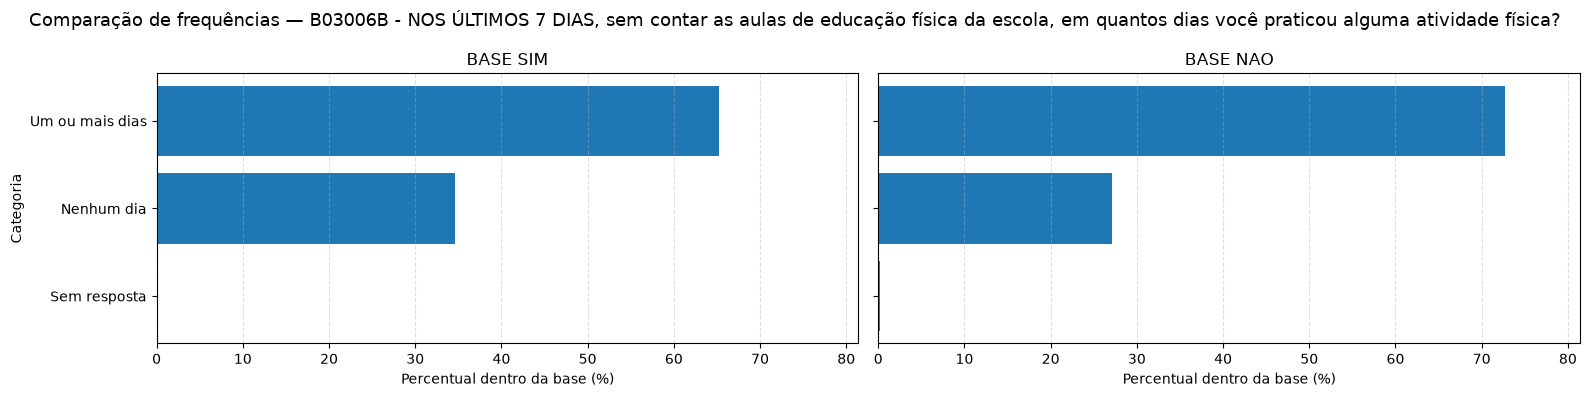


--------------------------------------------------------------------------------
VARIÁVEL: B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Um ou mais horas,30098,78.052955,59689,75.758037
Nenhuma hora,4591,11.905812,11234,14.258336
Sem resposta,3872,10.041233,7866,9.983627


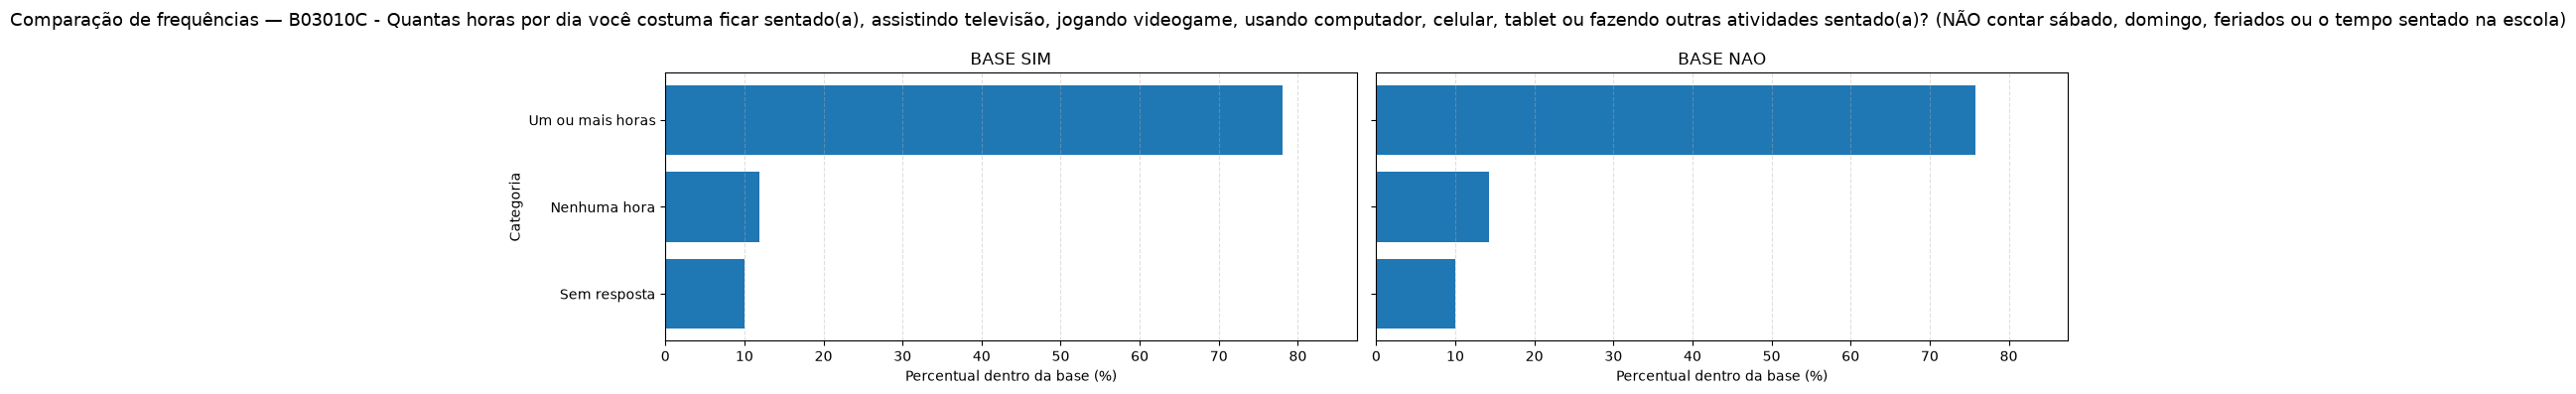


--------------------------------------------------------------------------------
VARIÁVEL: B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,24394,63.260808,36400,46.199343
Nao,14137,36.661394,42319,53.711813
Sem resposta,30,0.077799,70,0.088845


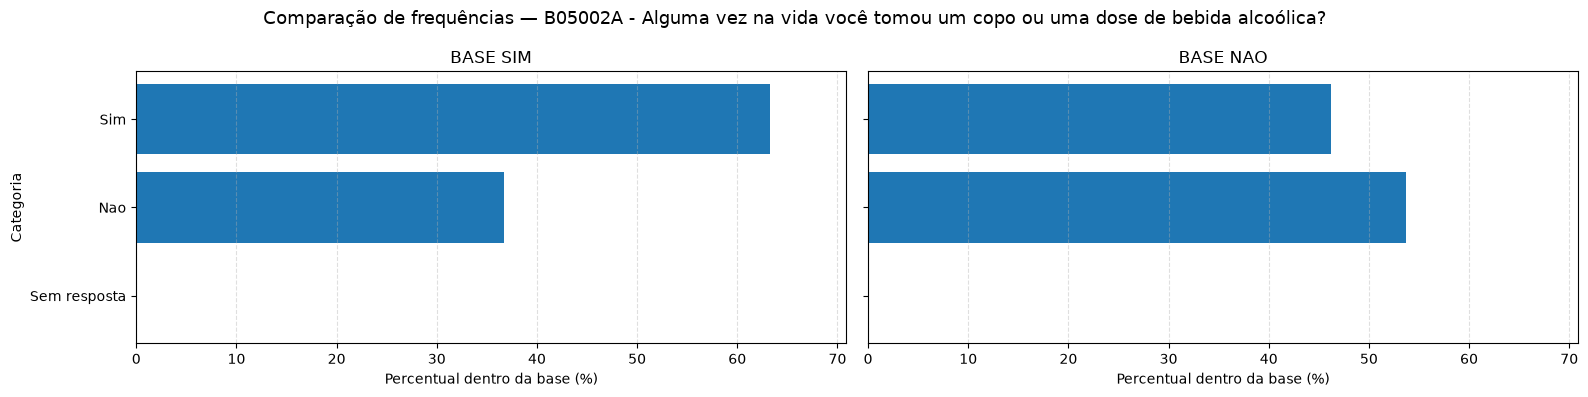


--------------------------------------------------------------------------------
VARIÁVEL: B07002 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável sabia realmente o que você estava fazendo em seu tempo livre?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sabia,23309,60.447084,56283,71.435099
Nunca/Raramente,8519,22.092269,11294,14.334488
As vezes,6661,17.27393,11018,13.984186
Sem resposta,72,0.186717,194,0.246227


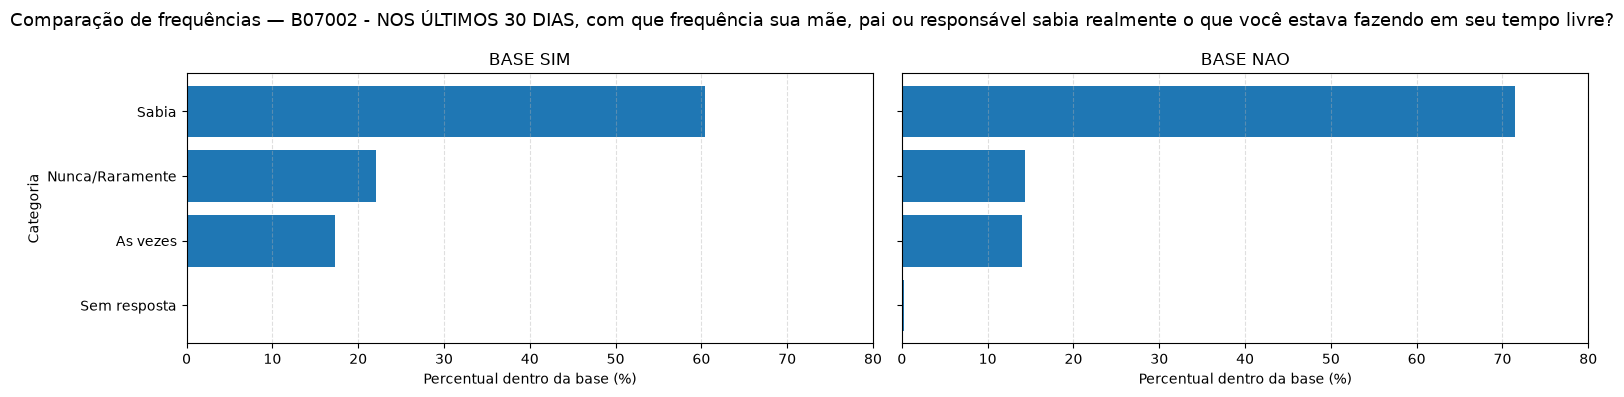


--------------------------------------------------------------------------------
VARIÁVEL: B07004 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável entendeu suas preocupações e problemas?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nunca/Raramente,19290,50.024636,22357,28.375788
Entendia,11279,29.24976,40001,50.769778
As vezes,7918,20.5337,16196,20.556169
Sem resposta,74,0.191904,235,0.298265


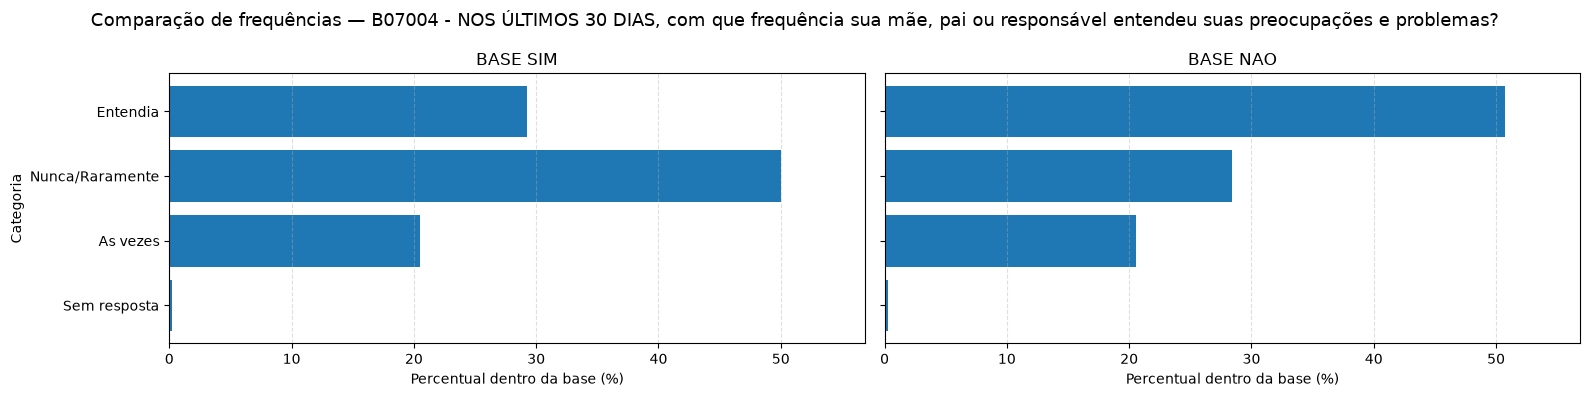


--------------------------------------------------------------------------------
VARIÁVEL: B07005 - NOS ÚLTIMOS 30 DIAS, com que frequência seus pais ou responsáveis mexeram em suas coisas sem a sua concordância?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nunca/Raramente,23359,60.576749,57875,73.455685
As vezes,7655,19.851664,12227,15.518664
Sempre,7490,19.42377,8508,10.798462
Sem resposta,57,0.147818,179,0.227189


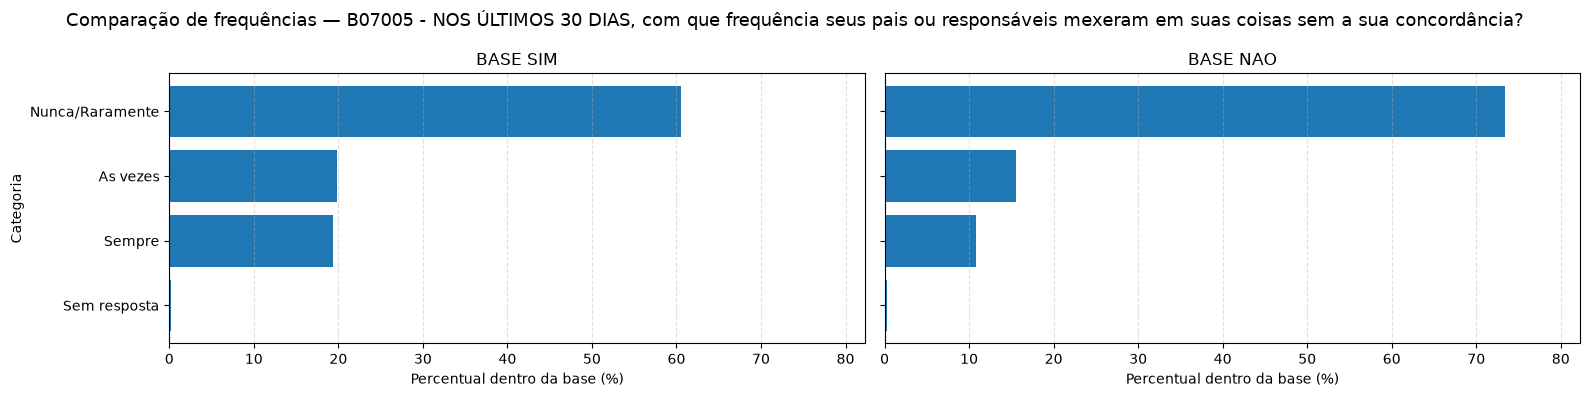


--------------------------------------------------------------------------------
VARIÁVEL: B07006 - NOS ÚLTIMOS 30 DIAS, com que frequência os colegas de sua escola trataram você bem e/ou foram prestativos com você?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,22740,58.9715,54505,69.178439
As vezes,8389,21.755141,13253,16.820876
Nao,7358,19.081455,10861,13.784919
Sem resposta,74,0.191904,170,0.215766


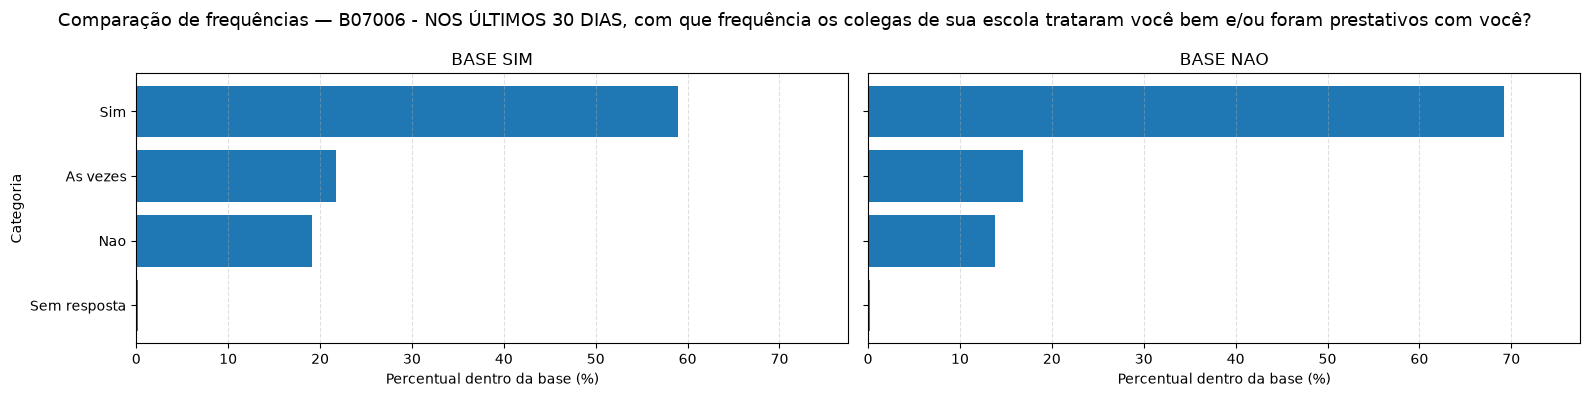


--------------------------------------------------------------------------------
VARIÁVEL: B07007B - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola o esculachou, zoou, mangou, intimidou ou caçoou tanto que você ficou magoado, incomodado, aborrecido, ofendido ou humilhado?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Uma ou mais vezes,20564,53.328493,26773,33.980632
Nenhuma vez,17914,46.456264,51820,65.770602
Sem resposta,83,0.215243,196,0.248766


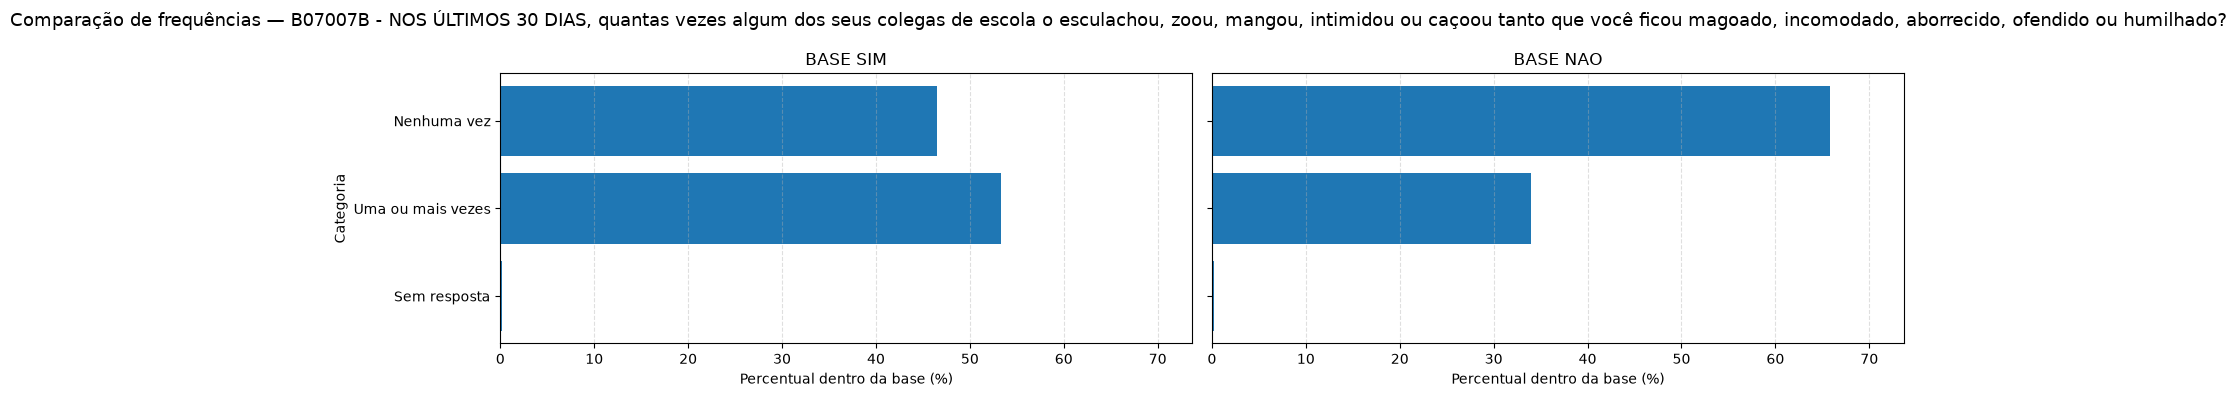


--------------------------------------------------------------------------------
VARIÁVEL: B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola se recusou a falar com você, deixou você de lado sem razão ou fez com que outros colegas deixassem de falar com você?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nenhuma vez,23887,61.946008,63026,79.9934
Uma ou mais vezes,14585,37.823189,15561,19.750219
Sem resposta,89,0.230803,202,0.256381


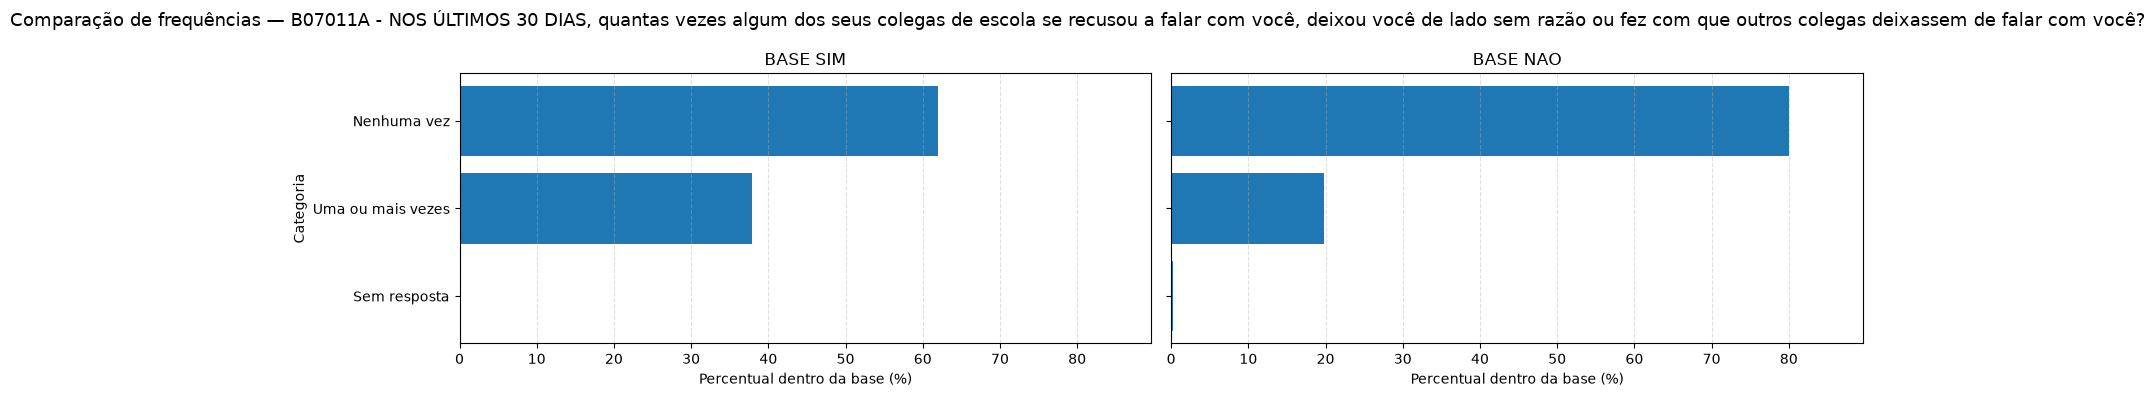


--------------------------------------------------------------------------------
VARIÁVEL: B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola bateu (deu socos, tapas, chutes, pontapés) em você ou o machucou fisicamente de outra forma?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nenhuma vez,29614,76.797801,67597,85.794971
Uma ou mais vezes,8867,22.994736,10987,13.94484
Sem resposta,80,0.207463,205,0.260189


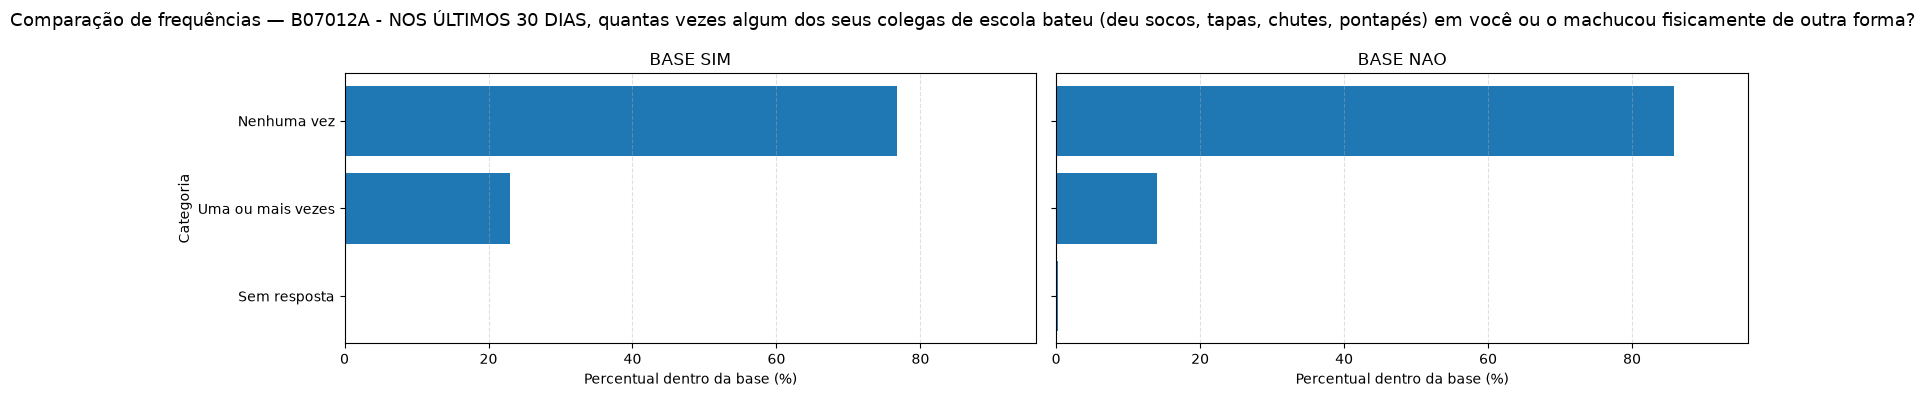


--------------------------------------------------------------------------------
VARIÁVEL: B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nao,30154,78.19818,72818,92.421531
Sim,8353,21.661783,5852,7.427433
Sem resposta,54,0.140038,119,0.151036


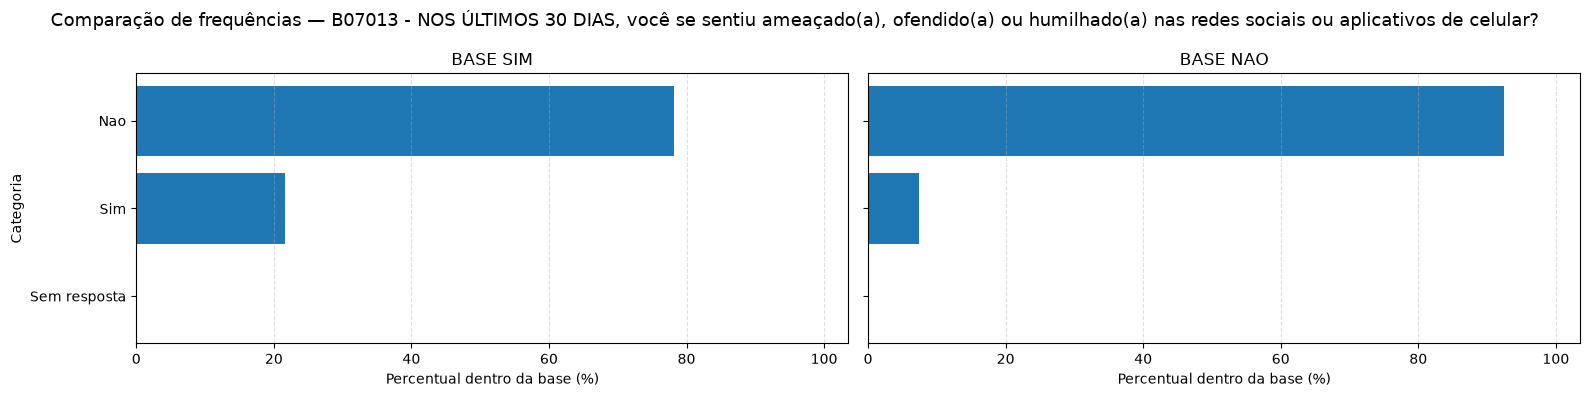


--------------------------------------------------------------------------------
VARIÁVEL: B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nao,31680,82.155546,69114,87.720367
Sim,6806,17.649957,9513,12.07402
Sem resposta,75,0.194497,162,0.205612


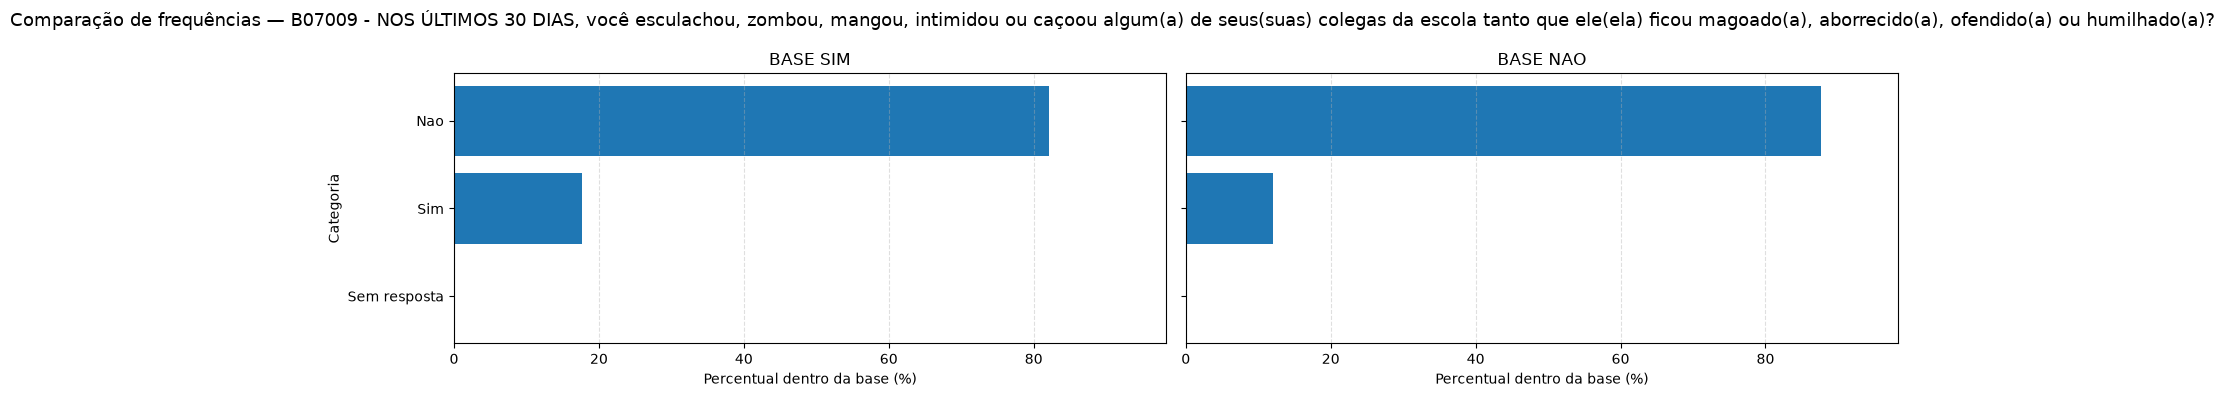


--------------------------------------------------------------------------------
VARIÁVEL: B07016 - NOS ÚLTIMOS 30 DIAS, você ameaçou, ofendeu ou humilhou outras pessoas nas redes sociais ou aplicativos de celular?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nao,32526,84.349472,72024,91.413776
Sim,5962,15.461217,6623,8.405996
Sem resposta,73,0.18931,142,0.180228


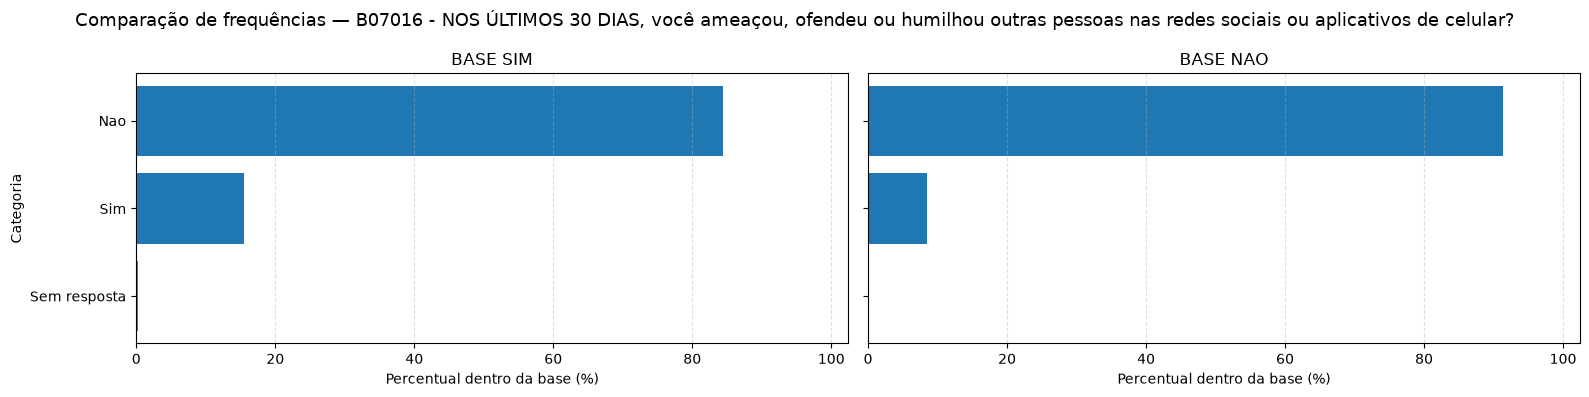


--------------------------------------------------------------------------------
VARIÁVEL: B12003 - Quantos(as) amigos(as) próximos você tem?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Mais que um,36461,94.554083,76153,96.654355
Nenhum,2060,5.342185,2542,3.226339
Sem resposta,40,0.103732,94,0.119306


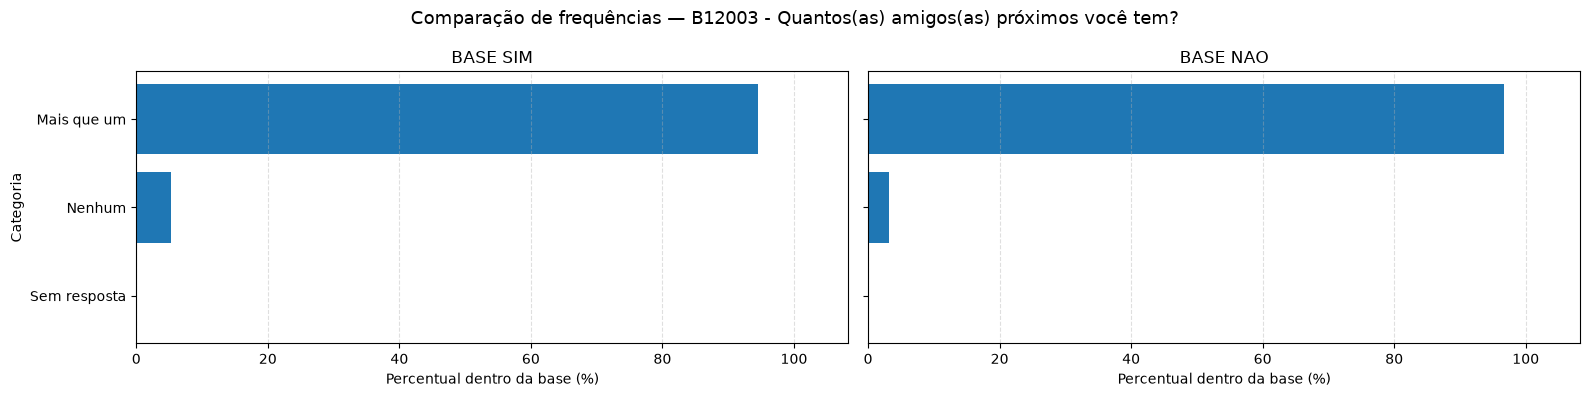


--------------------------------------------------------------------------------
VARIÁVEL: B12004 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu muito preocupado com as coisas comuns do seu dia a dia como atividades da escola, competições esportivas, tarefas de casa, etc.?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sempre,25127,65.161692,39458,50.080595
As vezes,7461,19.348565,21469,27.248728
Nunca/Raramente,5894,15.284873,17677,22.435873
Sem resposta,79,0.20487,185,0.234804


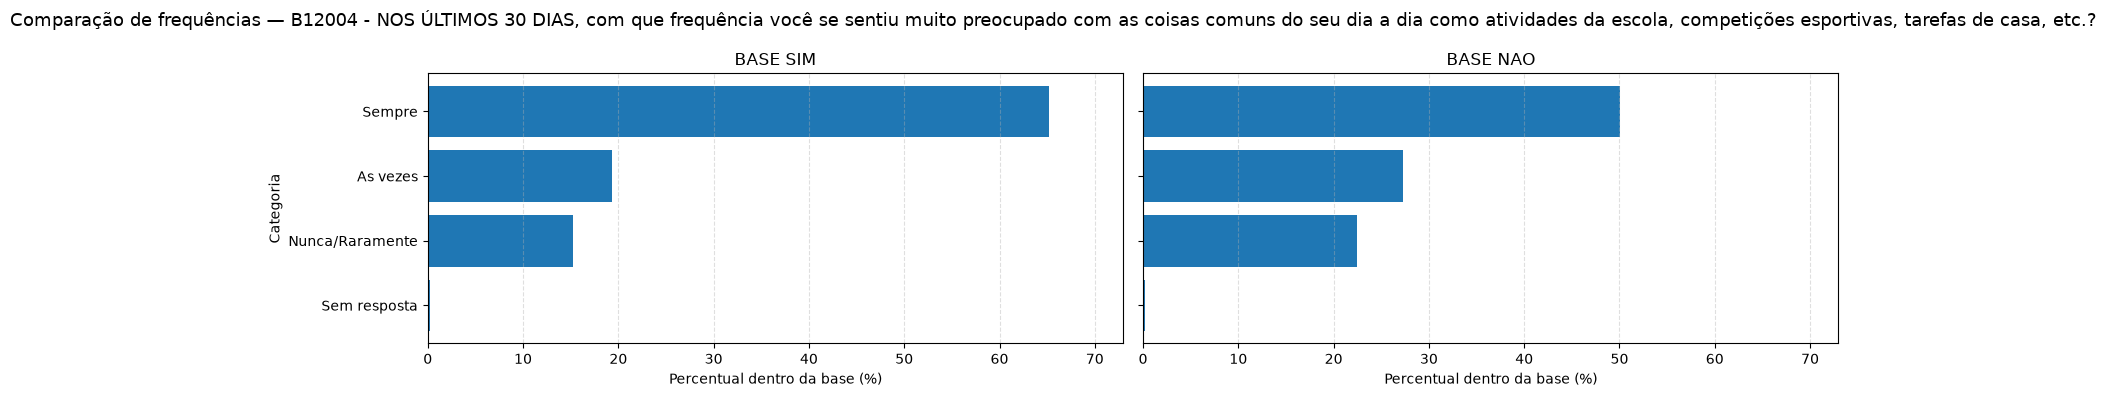


--------------------------------------------------------------------------------
VARIÁVEL: B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sempre,20783,53.896424,13362,16.95922
As vezes,12701,32.937424,30297,38.453337
Nunca/Raramente,5038,13.065014,35002,44.424983
Sem resposta,39,0.101138,128,0.162459


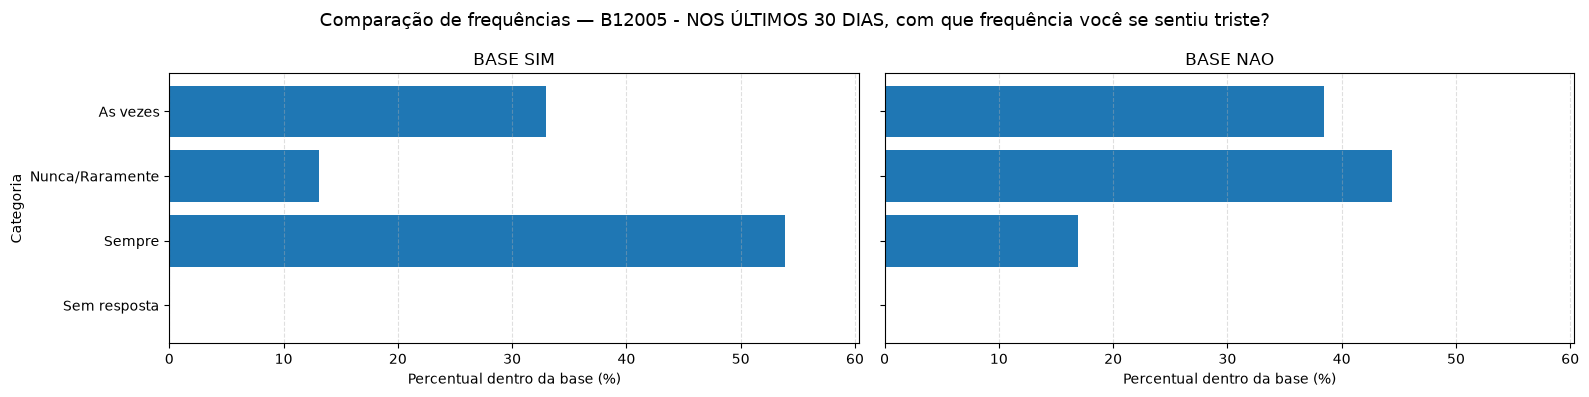


--------------------------------------------------------------------------------
VARIÁVEL: B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sempre,16792,43.546589,13031,16.539111
As vezes,11024,28.58847,18128,23.008288
Nunca/Raramente,10696,27.73787,47456,60.231758
Sem resposta,49,0.127071,174,0.220843


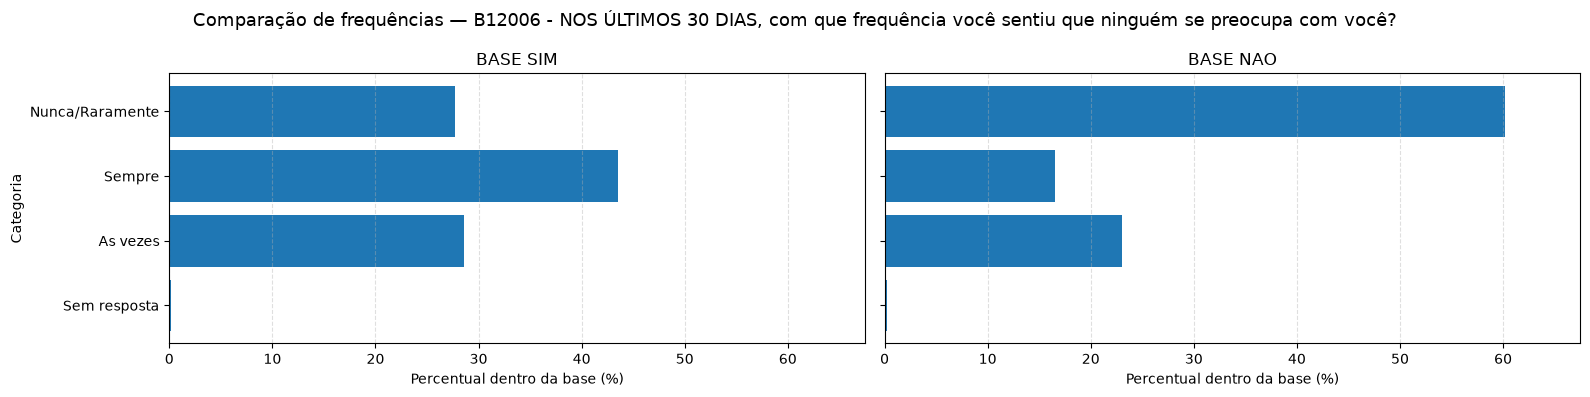


--------------------------------------------------------------------------------
VARIÁVEL: B12007 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu irritado(a), nervoso(a) ou mal-humorado(a) por qualquer coisa?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sempre,24074,62.430954,27390,34.763736
As vezes,9561,24.794481,28001,35.539225
Nunca/Raramente,4873,12.63712,23241,29.497773
Sem resposta,53,0.137445,157,0.199266


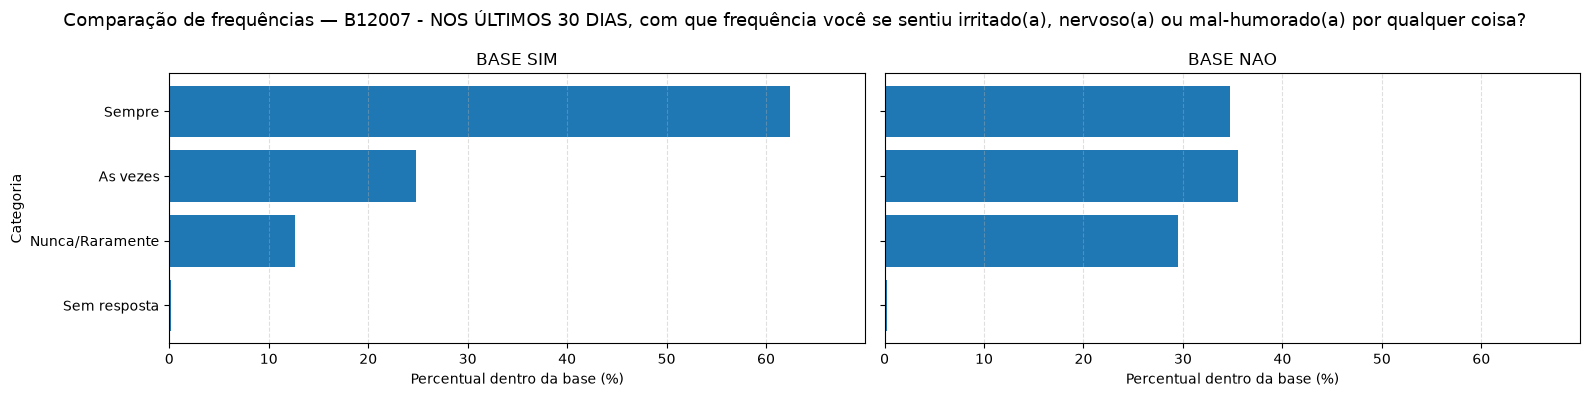


--------------------------------------------------------------------------------
VARIÁVEL: B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sempre,14775,38.315915,6103,7.746005
Nunca/Raramente,13964,36.212754,63645,80.779043
As vezes,9760,25.310547,8850,11.232532
Sem resposta,62,0.160784,191,0.24242


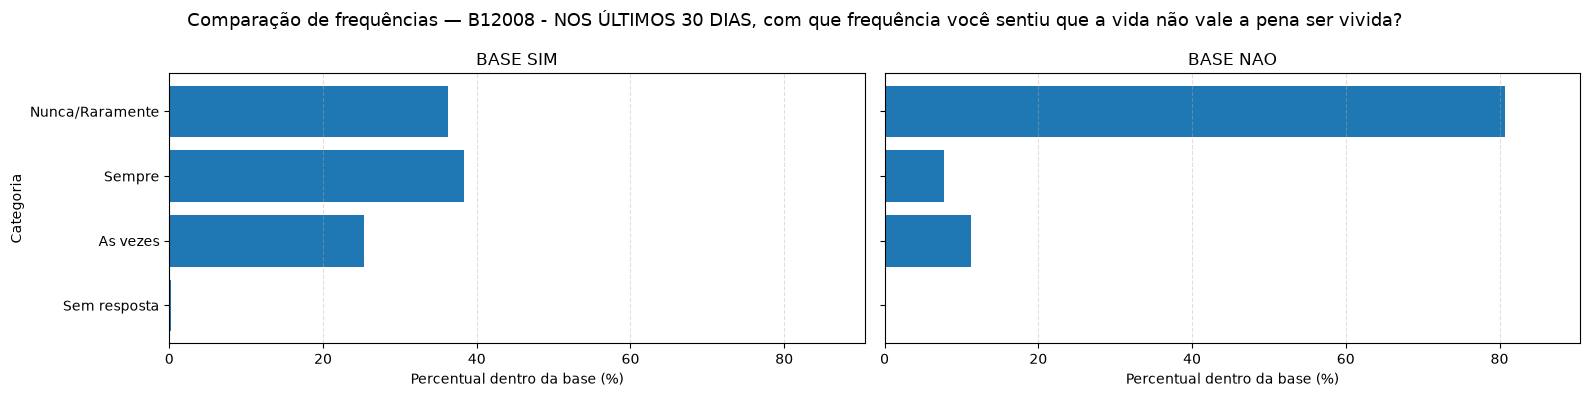


--------------------------------------------------------------------------------
VARIÁVEL: B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,38561,100.0,0,0.0
Nao,0,0.0,78789,100.0


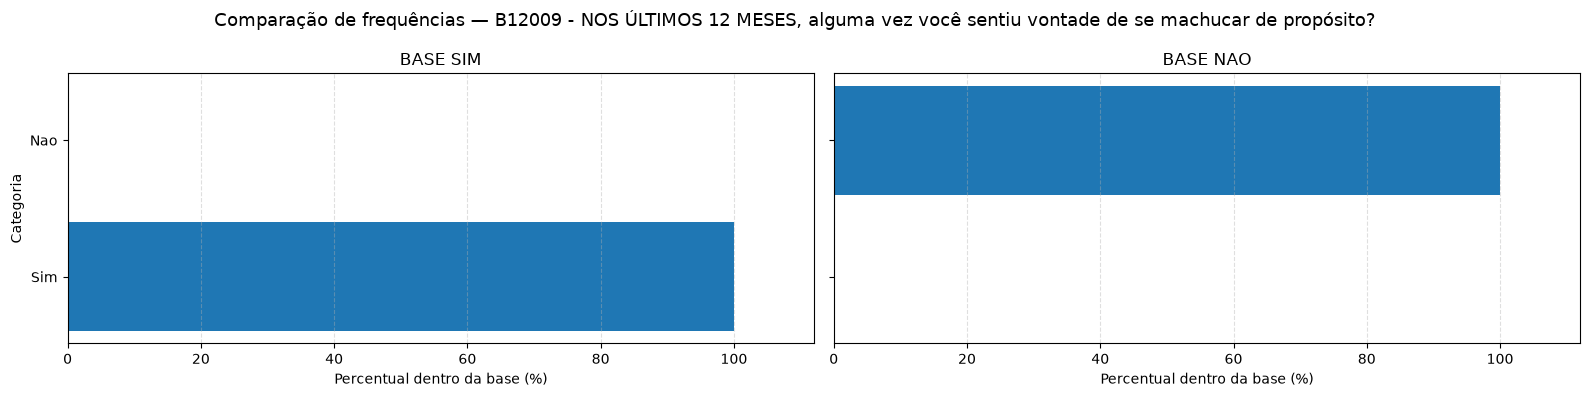


--------------------------------------------------------------------------------
VARIÁVEL: B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO de casa para a escola ou da escola para casa?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nenhum dia,33002,85.58388,71922,91.284316
1 ou mais dias,5334,13.832629,6381,8.098846
Sem resposta,225,0.583491,486,0.616837


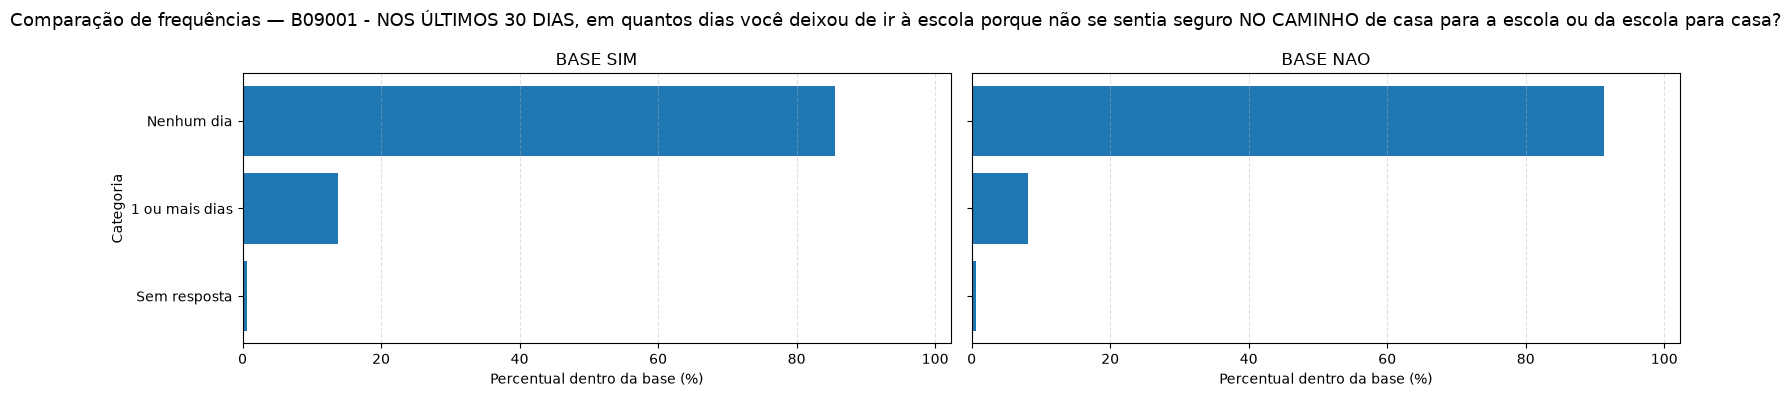


--------------------------------------------------------------------------------
VARIÁVEL: B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nenhum dia,30702,79.619304,72207,91.646042
1 ou mais dias,7629,19.784238,6053,7.682545
Sem resposta,230,0.596458,529,0.671414


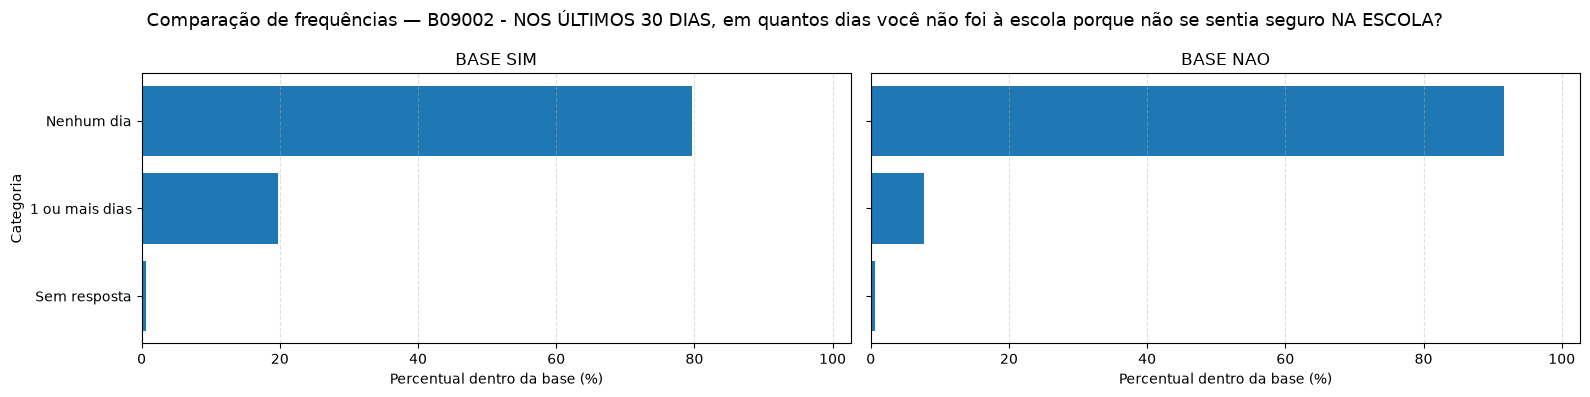


--------------------------------------------------------------------------------
VARIÁVEL: B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nenhuma vez,26577,68.921968,65999,83.766769
1 ou mais vezes,11715,30.380436,12239,15.533894
Sem resposta,269,0.697596,551,0.699336


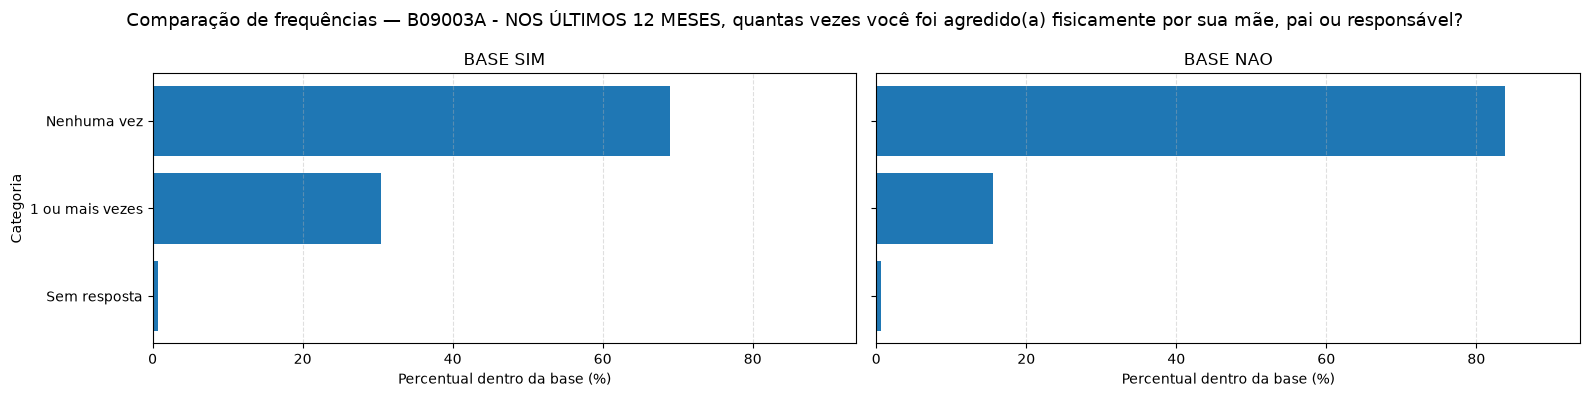


--------------------------------------------------------------------------------
VARIÁVEL: B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nenhuma vez,30510,79.121392,70308,89.235807
1 ou mais vezes,7784,20.186198,7901,10.02805
Sem resposta,267,0.692409,580,0.736143


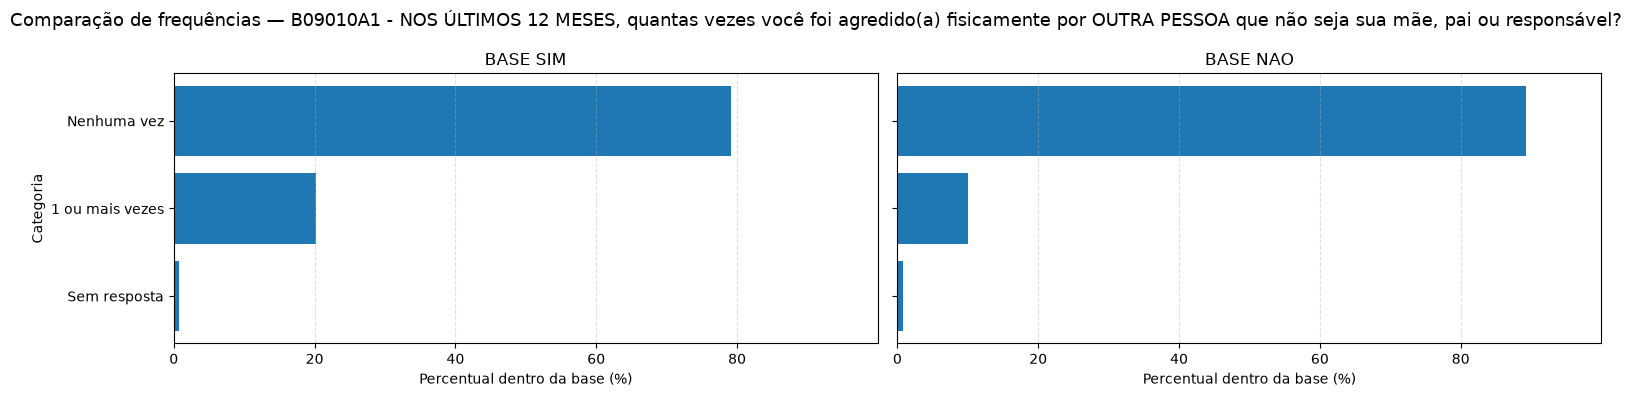


--------------------------------------------------------------------------------
VARIÁVEL: B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nao,25110,65.117606,69295,87.950095
Sim,13138,34.070693,8937,11.342954
Sem resposta,313,0.811701,557,0.706951


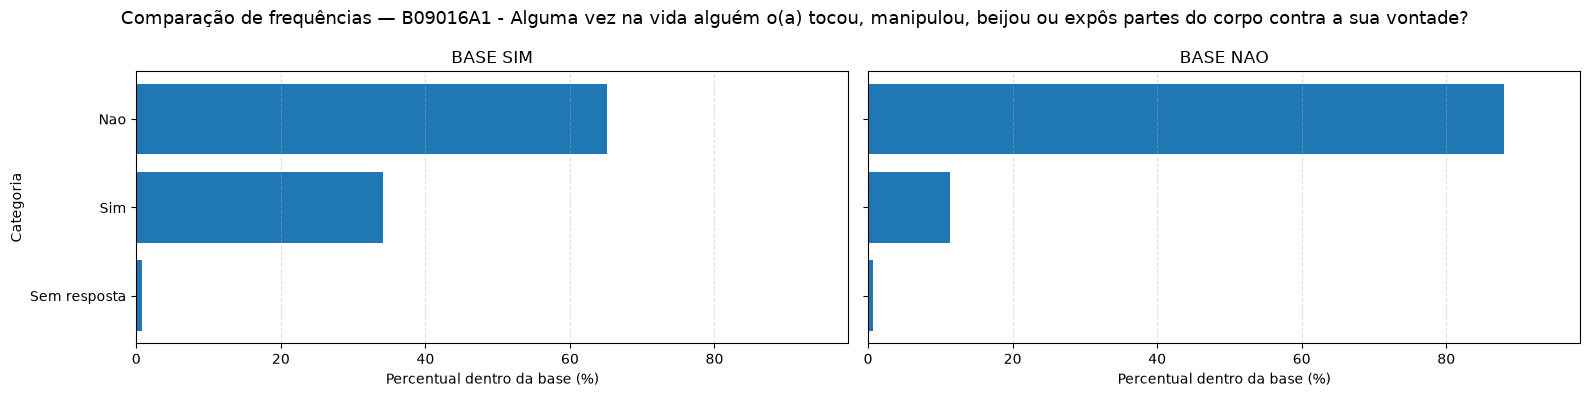


--------------------------------------------------------------------------------
VARIÁVEL: B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nao,31969,82.905008,74974,95.157954
Sim,6265,16.246985,3223,4.090673
Sem resposta,327,0.848007,592,0.751374


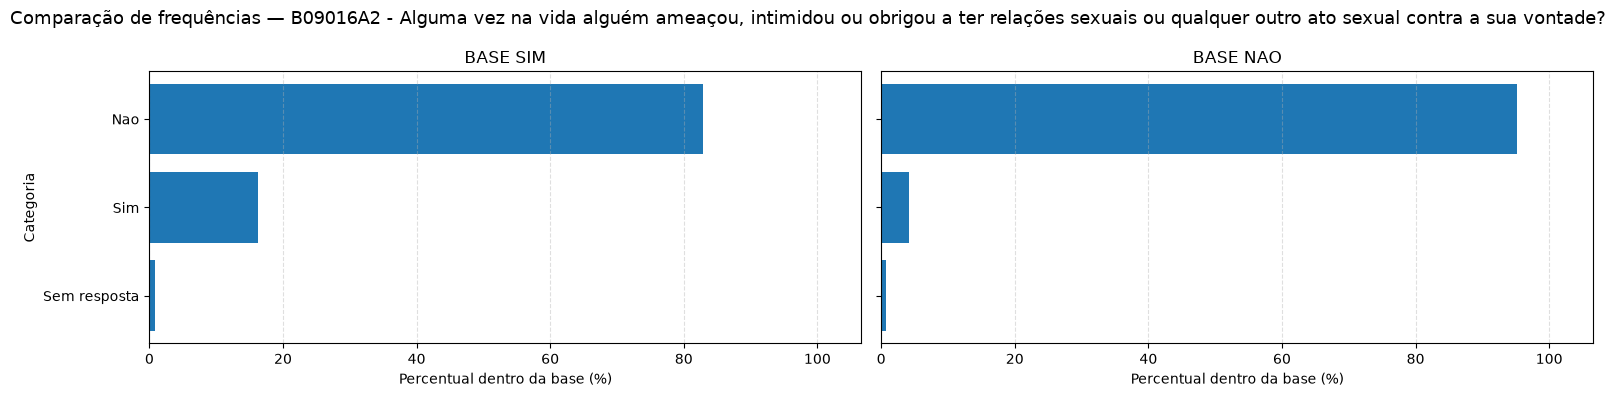


--------------------------------------------------------------------------------
VARIÁVEL: E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,21607,56.033298,43655,55.407481
Nao,16763,43.471383,34805,44.174948
Sem resposta,191,0.495319,329,0.417571


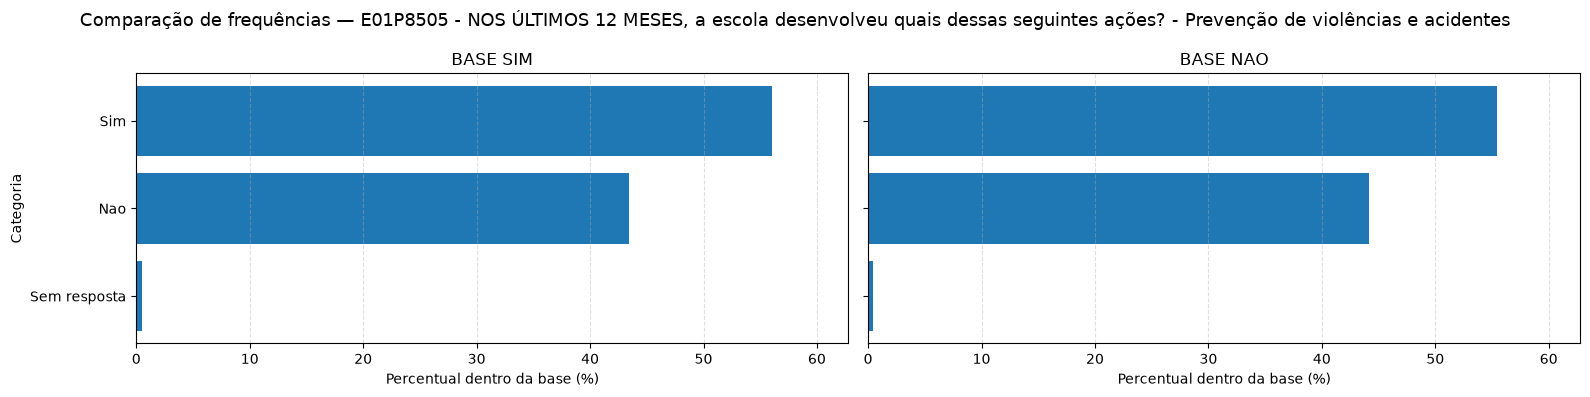


--------------------------------------------------------------------------------
VARIÁVEL: E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,19712,51.119006,40308,51.159426
Nao,18658,48.385675,38152,48.423003
Sem resposta,191,0.495319,329,0.417571


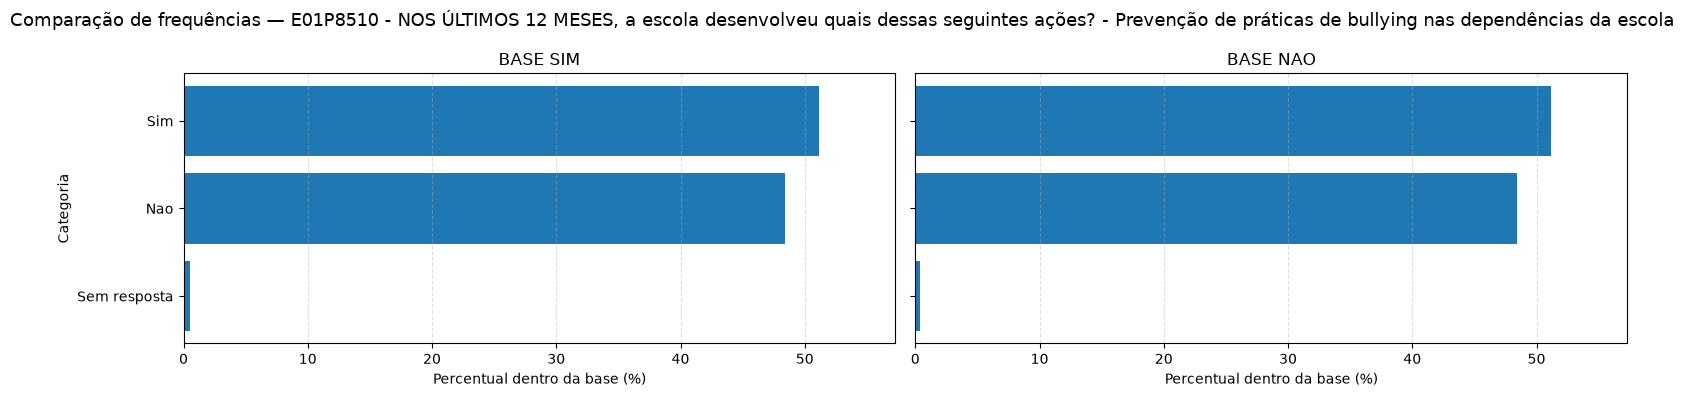


--------------------------------------------------------------------------------
VARIÁVEL: E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Sim,31625,82.012915,64531,81.903565
Não,6892,17.87298,14159,17.970783
0,44,0.114105,99,0.125652


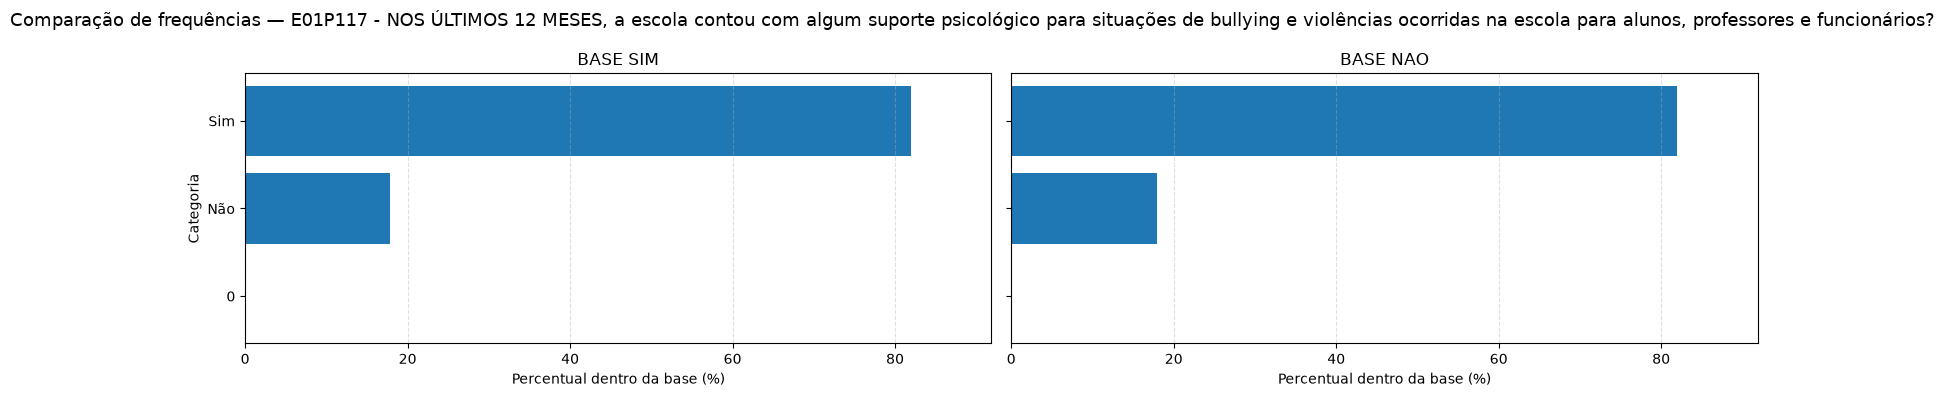


--------------------------------------------------------------------------------
VARIÁVEL: E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nao,16467,42.703768,32944,41.812943
Sim,14968,38.816421,31218,39.622282
Sem resposta,7126,18.479811,14627,18.564774


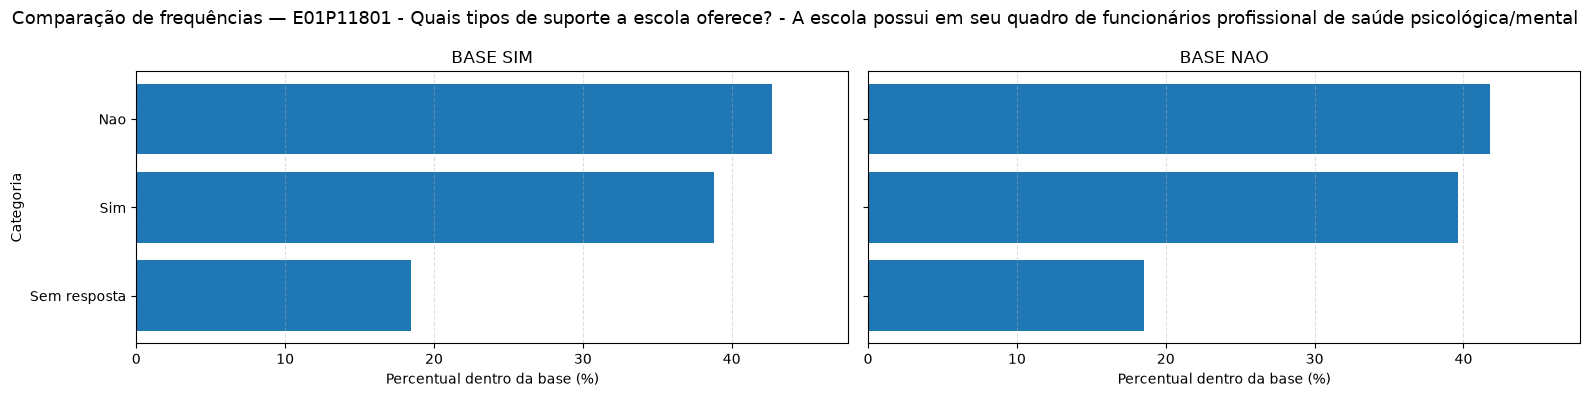


--------------------------------------------------------------------------------
VARIÁVEL: E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
--------------------------------------------------------------------------------


,Frequência SIM,Percentual SIM (%),Frequência NAO,Percentual NAO (%)
Categoria,,,,
Nao,25733,66.733228,52350,66.443285
Sem resposta,7126,18.479811,14627,18.564774
Sim,5702,14.786961,11812,14.99194


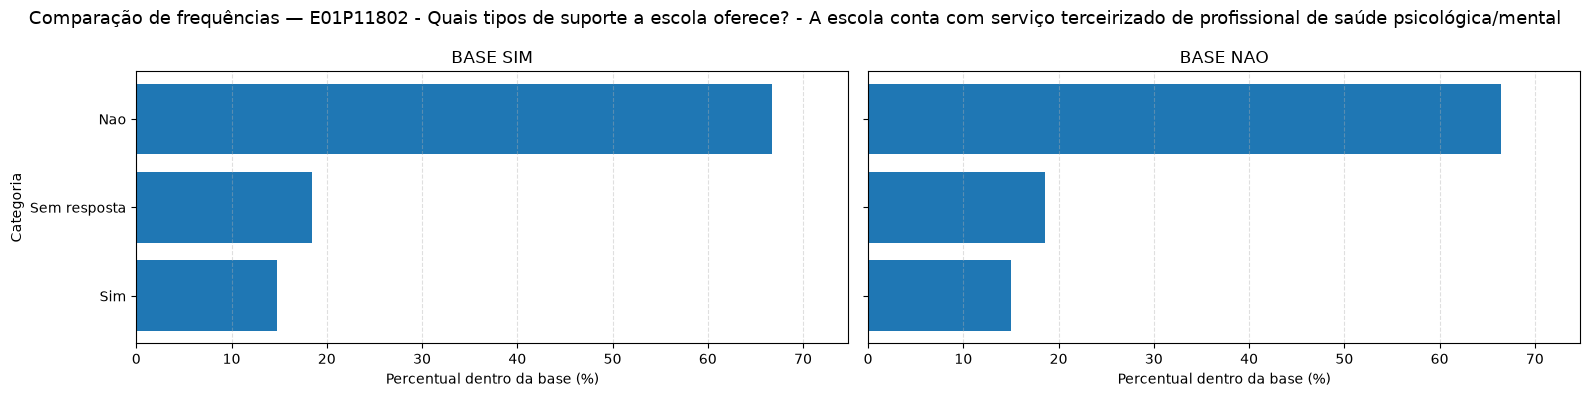


CORRELAÇÕES — BASE SIM
Matriz de correlação:


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
REGIAO - código de regiões,1.000000,0.984347,0.029936,-0.006994,-0.020778,-0.164090,0.038965,0.038862,0.157827,0.071098,...,-0.019790,0.003665,0.003067,-0.013043,-0.031278,0.023624,0.000675,0.038910,-0.061693,0.012324
UF - código UF,0.984347,1.000000,0.031662,-0.006255,-0.020417,-0.161597,0.043415,0.038036,0.151934,0.074633,...,-0.020109,0.004045,0.003275,-0.012846,-0.032296,0.014578,-0.003000,0.036464,-0.049585,0.015959
CAPITAL - indica se é município da capital,0.029936,0.031662,1.000000,-0.013866,0.021921,-0.062916,0.009860,-0.021867,0.122373,0.054852,...,0.003133,0.012701,0.024019,0.022768,-0.005441,0.018716,0.016745,-0.008804,0.049892,-0.036738
B01001A - Qual é o seu sexo?,-0.006994,-0.006255,-0.013866,1.000000,-0.006886,-0.001902,0.009176,-0.042698,-0.041240,0.016550,...,0.011998,0.001157,-0.110301,0.173017,0.084940,-0.005668,-0.005410,0.000964,-0.008415,0.003587
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",-0.020778,-0.020417,0.021921,-0.006886,1.000000,-0.023902,-0.056438,-0.041032,-0.012301,-0.017862,...,-0.047442,-0.100184,-0.088441,0.063409,0.048913,-0.006743,-0.012634,-0.033737,0.041775,0.002829
B01002 - Qual é a sua cor ou raça?,-0.164090,-0.161597,-0.062916,-0.001902,-0.023902,1.000000,-0.046512,-0.057219,-0.201419,-0.071288,...,0.020305,0.005871,0.002379,-0.014456,0.014906,-0.019617,-0.010131,0.032192,-0.070289,-0.031080
B01006 - Você mora com sua mãe?,0.038965,0.043415,0.009860,0.009176,-0.056438,-0.046512,1.000000,0.102968,0.087980,0.039607,...,-0.006195,0.024449,0.003270,-0.034747,-0.048611,0.005266,0.010168,-0.013519,0.030467,0.012215
B01007 - Você mora com seu pai?,0.038862,0.038036,-0.021867,-0.042698,-0.041032,-0.057219,0.102968,1.000000,0.180012,0.025178,...,-0.046063,-0.019958,-0.002472,-0.063606,-0.059530,0.015587,0.018940,-0.019567,0.054323,0.021468
B01015B - Na sua casa tem computador ou notebook?,0.157827,0.151934,0.122373,-0.041240,-0.012301,-0.201419,0.087980,0.180012,1.000000,0.170388,...,-0.071106,-0.007009,0.012015,-0.004452,-0.062669,0.049215,0.032892,-0.084780,0.174421,0.062724
B01016 - Você tem acesso à internet em sua casa?,0.071098,0.074633,0.054852,0.016550,-0.017862,-0.071288,0.039607,0.025178,0.170388,1.000000,...,-0.050809,-0.019187,-0.036176,-0.011343,-0.046892,0.025388,0.019477,-0.039615,0.062

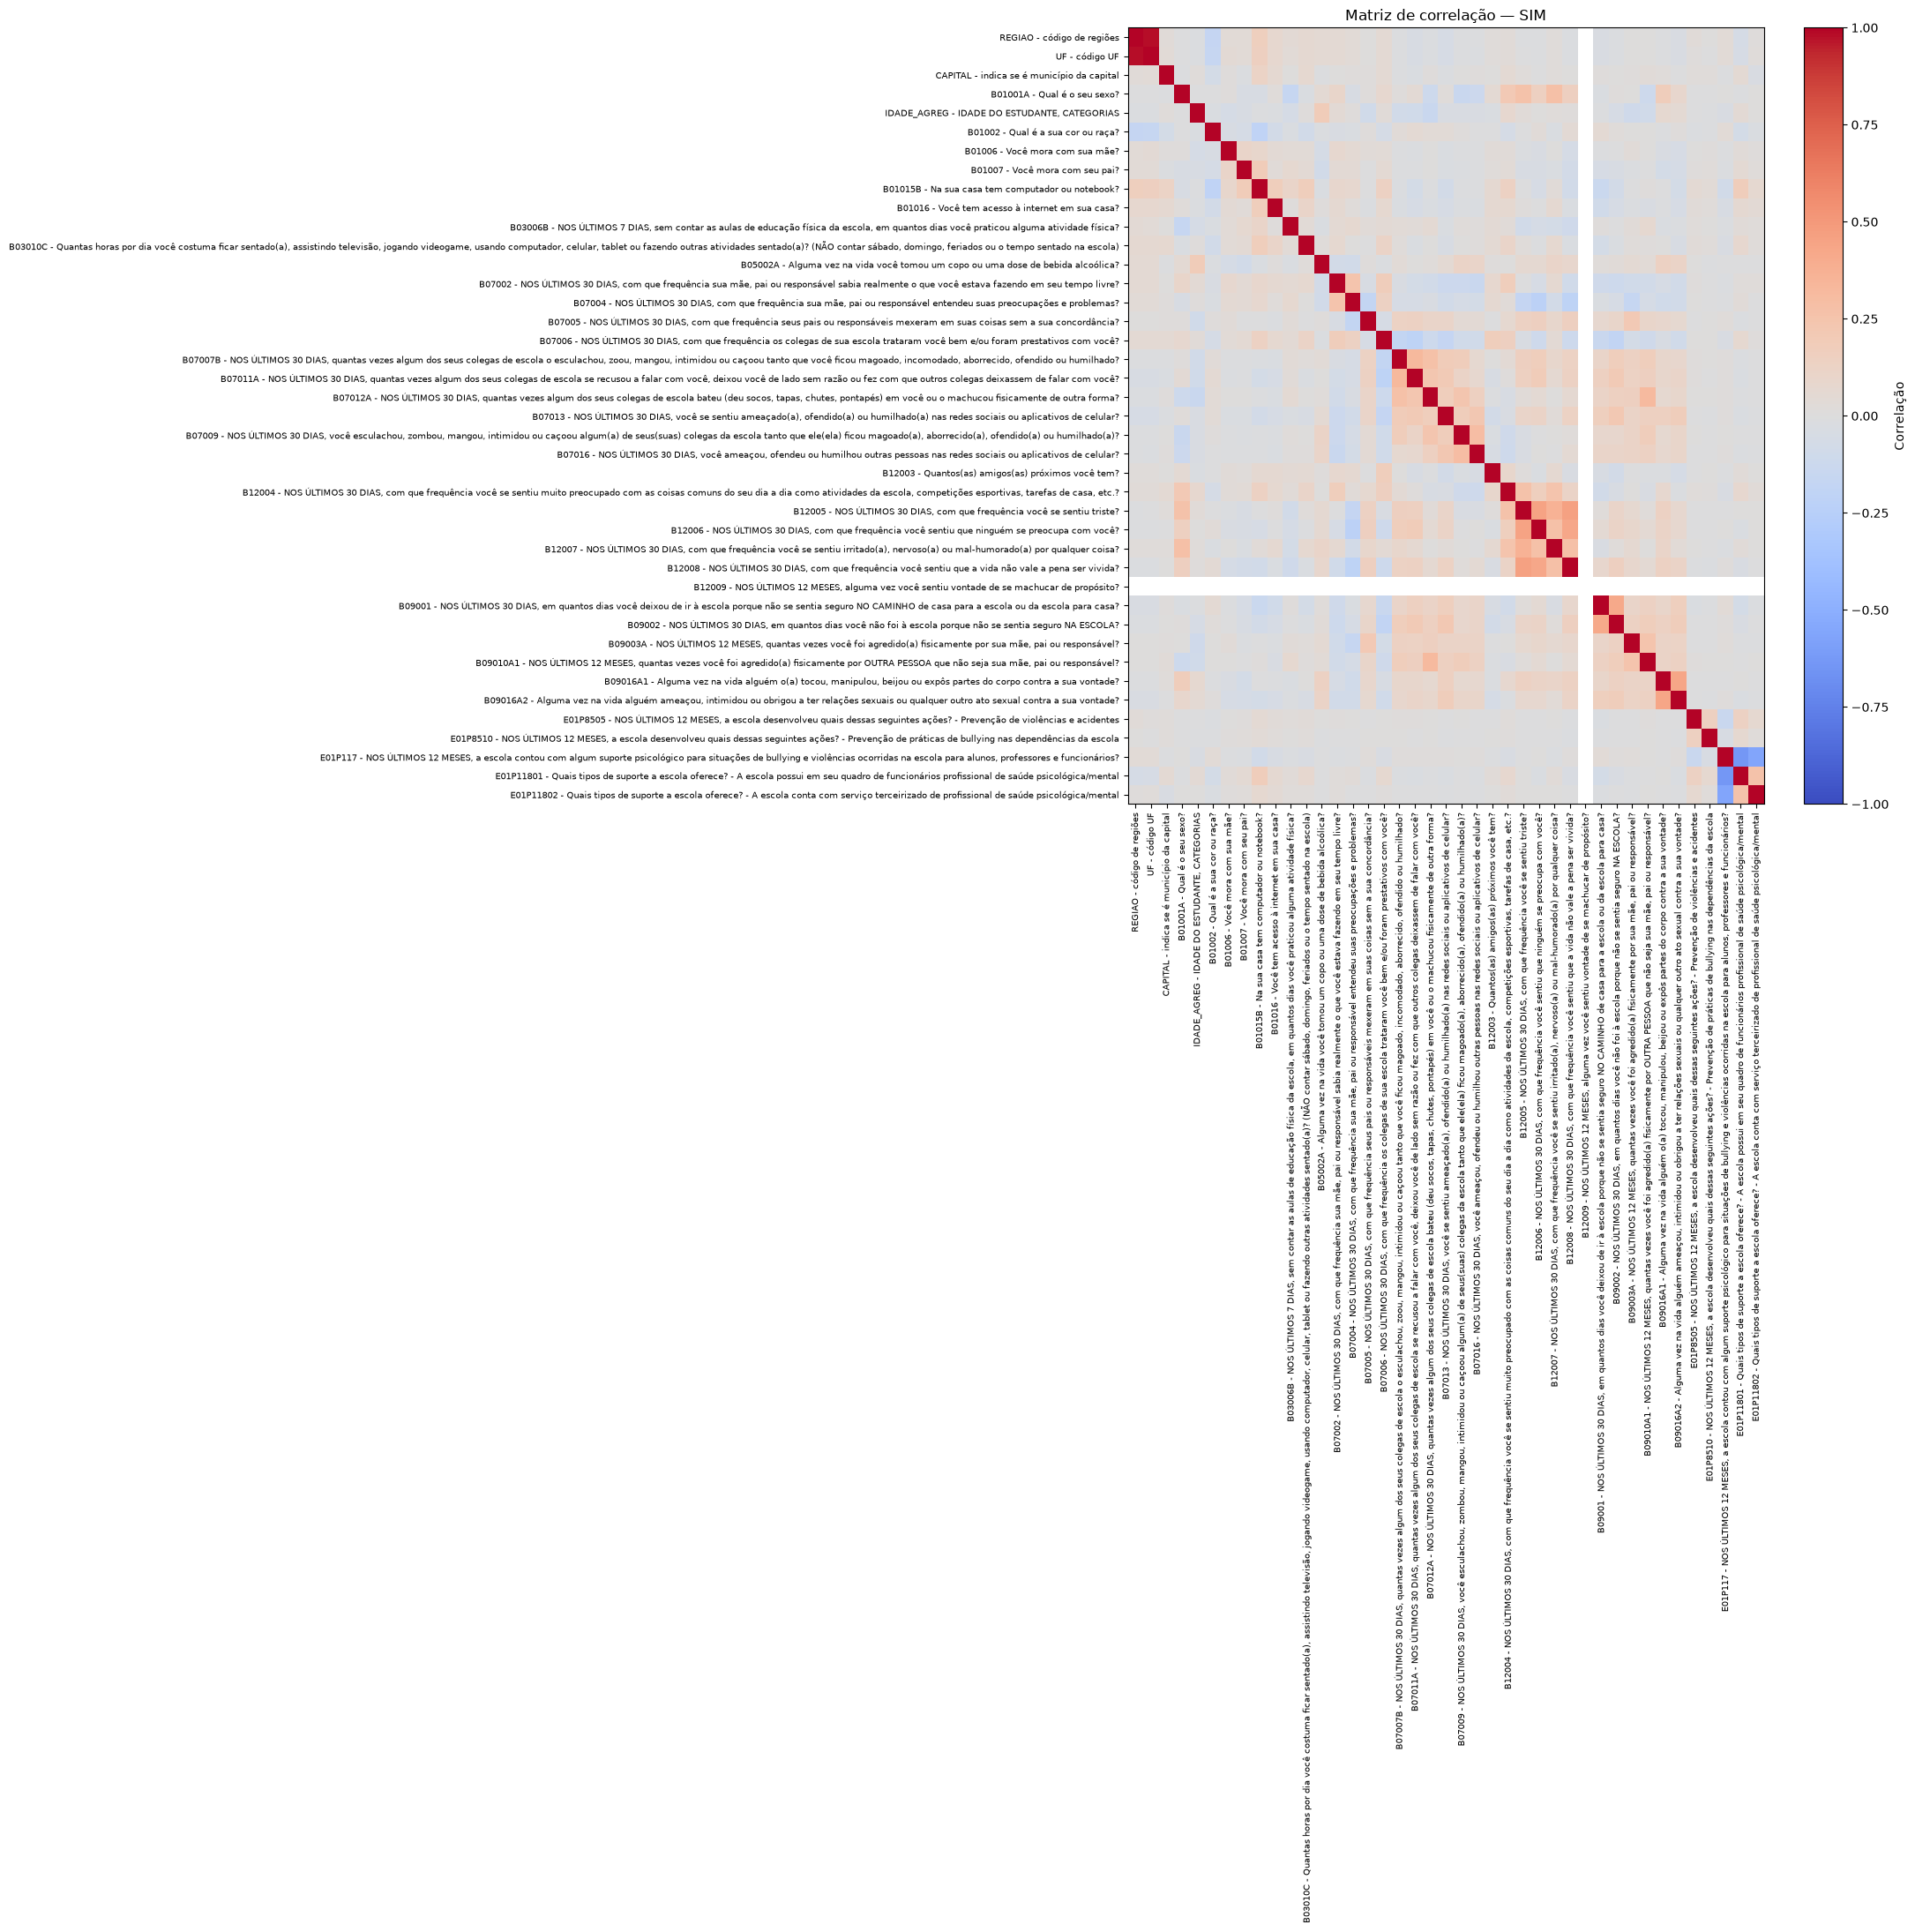


CORRELAÇÕES — BASE NAO
Matriz de correlação:


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
REGIAO - código de regiões,1.000000,0.983716,0.047437,-0.002185,-0.020637,-0.176073,0.041973,0.040677,0.167710,0.077636,...,-0.018534,-0.000539,0.003014,-0.016196,-0.019497,0.036031,0.007102,0.029907,-0.060545,0.019461
UF - código UF,0.983716,1.000000,0.047113,-0.001262,-0.022212,-0.172258,0.044482,0.038118,0.160606,0.081479,...,-0.019727,0.000170,0.003625,-0.018075,-0.021060,0.027424,0.003156,0.028247,-0.049545,0.023399
CAPITAL - indica se é município da capital,0.047437,0.047113,1.000000,-0.007651,0.012449,-0.078299,0.003698,-0.025245,0.139195,0.064363,...,-0.007287,0.021097,0.023970,0.014904,-0.005434,0.037331,0.023322,-0.028890,0.064511,-0.019158
B01001A - Qual é o seu sexo?,-0.002185,-0.001262,-0.007651,1.000000,0.012639,-0.020614,0.029372,-0.018643,0.004716,0.007391,...,0.000237,-0.038360,-0.077373,0.130970,0.058828,-0.004179,-0.002253,-0.001788,0.011407,-0.004765
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",-0.020637,-0.022212,0.012449,0.012639,1.000000,-0.013844,-0.050656,-0.046925,-0.016773,-0.015445,...,-0.016846,-0.073112,-0.056651,0.058143,0.032147,-0.002171,-0.014592,-0.030252,0.034703,-0.004259
B01002 - Qual é a sua cor ou raça?,-0.176073,-0.172258,-0.078299,-0.020614,-0.013844,1.000000,-0.042165,-0.049062,-0.209253,-0.082663,...,0.032349,0.007695,-0.008723,-0.002891,0.013374,-0.027343,-0.018778,0.028483,-0.069675,-0.028655
B01006 - Você mora com sua mãe?,0.041973,0.044482,0.003698,0.029372,-0.050656,-0.042165,1.000000,0.116058,0.087658,0.030931,...,-0.021414,0.004677,-0.008525,-0.023868,-0.030172,0.003277,0.008650,-0.009960,0.026331,0.008553
B01007 - Você mora com seu pai?,0.040677,0.038118,-0.025245,-0.018643,-0.046925,-0.049062,0.116058,1.000000,0.169330,0.022126,...,-0.032849,-0.018881,-0.001631,-0.038795,-0.035230,0.014931,0.019375,-0.020416,0.050025,0.017650
B01015B - Na sua casa tem computador ou notebook?,0.167710,0.160606,0.139195,0.004716,-0.016773,-0.209253,0.087658,0.169330,1.000000,0.180517,...,-0.070900,0.002798,0.022771,0.001191,-0.031151,0.060442,0.047980,-0.088743,0.170891,0.069797
B01016 - Você tem acesso à internet em sua casa?,0.077636,0.081479,0.064363,0.007391,-0.015445,-0.082663,0.030931,0.022126,0.180517,1.000000,...,-0.057694,-0.016972,-0.013585,-0.006660,-0.023210,0.032592,0.025513,-0.046045,0.066

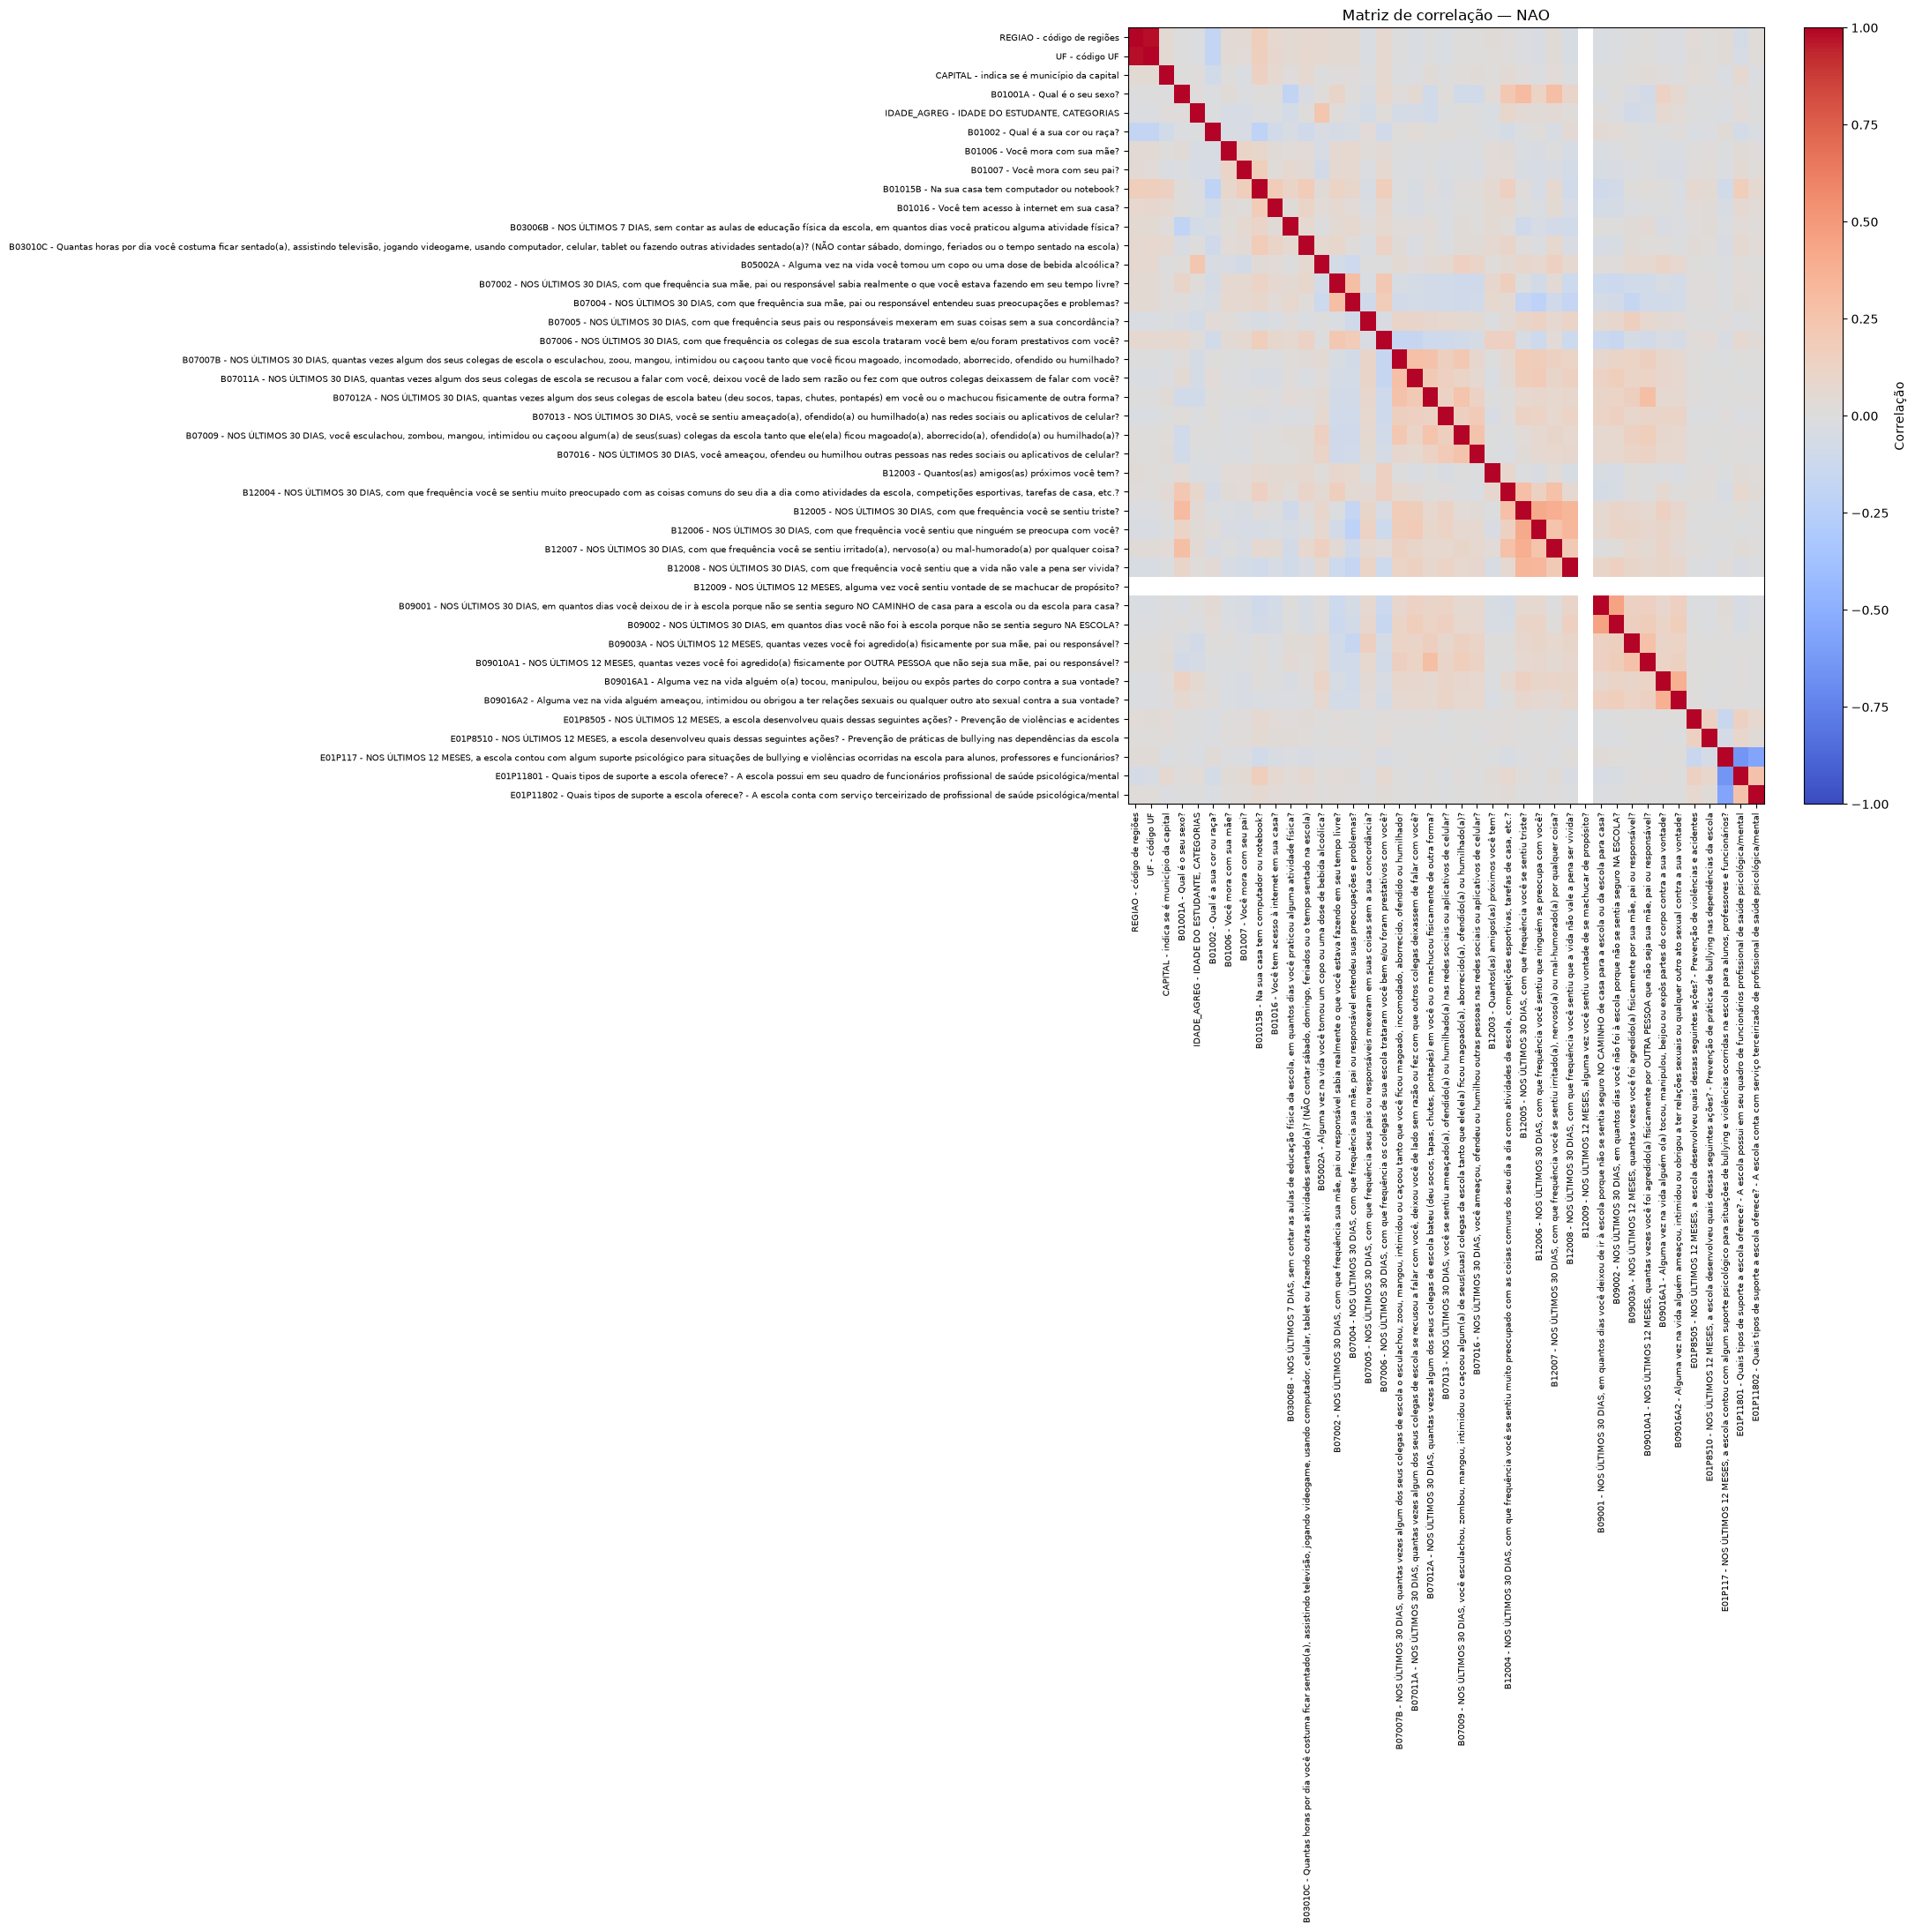


CORRELAÇÃO — VARIÁVEIS NUMÉRICAS COMUNS

Matriz SIM:


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
REGIAO - código de regiões,1.000000,0.984347,0.029936,-0.006994,-0.020778,-0.164090,0.038965,0.038862,0.157827,0.071098,...,-0.019790,0.003665,0.003067,-0.013043,-0.031278,0.023624,0.000675,0.038910,-0.061693,0.012324
UF - código UF,0.984347,1.000000,0.031662,-0.006255,-0.020417,-0.161597,0.043415,0.038036,0.151934,0.074633,...,-0.020109,0.004045,0.003275,-0.012846,-0.032296,0.014578,-0.003000,0.036464,-0.049585,0.015959
CAPITAL - indica se é município da capital,0.029936,0.031662,1.000000,-0.013866,0.021921,-0.062916,0.009860,-0.021867,0.122373,0.054852,...,0.003133,0.012701,0.024019,0.022768,-0.005441,0.018716,0.016745,-0.008804,0.049892,-0.036738
B01001A - Qual é o seu sexo?,-0.006994,-0.006255,-0.013866,1.000000,-0.006886,-0.001902,0.009176,-0.042698,-0.041240,0.016550,...,0.011998,0.001157,-0.110301,0.173017,0.084940,-0.005668,-0.005410,0.000964,-0.008415,0.003587
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",-0.020778,-0.020417,0.021921,-0.006886,1.000000,-0.023902,-0.056438,-0.041032,-0.012301,-0.017862,...,-0.047442,-0.100184,-0.088441,0.063409,0.048913,-0.006743,-0.012634,-0.033737,0.041775,0.002829
B01002 - Qual é a sua cor ou raça?,-0.164090,-0.161597,-0.062916,-0.001902,-0.023902,1.000000,-0.046512,-0.057219,-0.201419,-0.071288,...,0.020305,0.005871,0.002379,-0.014456,0.014906,-0.019617,-0.010131,0.032192,-0.070289,-0.031080
B01006 - Você mora com sua mãe?,0.038965,0.043415,0.009860,0.009176,-0.056438,-0.046512,1.000000,0.102968,0.087980,0.039607,...,-0.006195,0.024449,0.003270,-0.034747,-0.048611,0.005266,0.010168,-0.013519,0.030467,0.012215
B01007 - Você mora com seu pai?,0.038862,0.038036,-0.021867,-0.042698,-0.041032,-0.057219,0.102968,1.000000,0.180012,0.025178,...,-0.046063,-0.019958,-0.002472,-0.063606,-0.059530,0.015587,0.018940,-0.019567,0.054323,0.021468
B01015B - Na sua casa tem computador ou notebook?,0.157827,0.151934,0.122373,-0.041240,-0.012301,-0.201419,0.087980,0.180012,1.000000,0.170388,...,-0.071106,-0.007009,0.012015,-0.004452,-0.062669,0.049215,0.032892,-0.084780,0.174421,0.062724
B01016 - Você tem acesso à internet em sua casa?,0.071098,0.074633,0.054852,0.016550,-0.017862,-0.071288,0.039607,0.025178,0.170388,1.000000,...,-0.050809,-0.019187,-0.036176,-0.011343,-0.046892,0.025388,0.019477,-0.039615,0.062


Matriz NAO:


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
REGIAO - código de regiões,1.000000,0.983716,0.047437,-0.002185,-0.020637,-0.176073,0.041973,0.040677,0.167710,0.077636,...,-0.018534,-0.000539,0.003014,-0.016196,-0.019497,0.036031,0.007102,0.029907,-0.060545,0.019461
UF - código UF,0.983716,1.000000,0.047113,-0.001262,-0.022212,-0.172258,0.044482,0.038118,0.160606,0.081479,...,-0.019727,0.000170,0.003625,-0.018075,-0.021060,0.027424,0.003156,0.028247,-0.049545,0.023399
CAPITAL - indica se é município da capital,0.047437,0.047113,1.000000,-0.007651,0.012449,-0.078299,0.003698,-0.025245,0.139195,0.064363,...,-0.007287,0.021097,0.023970,0.014904,-0.005434,0.037331,0.023322,-0.028890,0.064511,-0.019158
B01001A - Qual é o seu sexo?,-0.002185,-0.001262,-0.007651,1.000000,0.012639,-0.020614,0.029372,-0.018643,0.004716,0.007391,...,0.000237,-0.038360,-0.077373,0.130970,0.058828,-0.004179,-0.002253,-0.001788,0.011407,-0.004765
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",-0.020637,-0.022212,0.012449,0.012639,1.000000,-0.013844,-0.050656,-0.046925,-0.016773,-0.015445,...,-0.016846,-0.073112,-0.056651,0.058143,0.032147,-0.002171,-0.014592,-0.030252,0.034703,-0.004259
B01002 - Qual é a sua cor ou raça?,-0.176073,-0.172258,-0.078299,-0.020614,-0.013844,1.000000,-0.042165,-0.049062,-0.209253,-0.082663,...,0.032349,0.007695,-0.008723,-0.002891,0.013374,-0.027343,-0.018778,0.028483,-0.069675,-0.028655
B01006 - Você mora com sua mãe?,0.041973,0.044482,0.003698,0.029372,-0.050656,-0.042165,1.000000,0.116058,0.087658,0.030931,...,-0.021414,0.004677,-0.008525,-0.023868,-0.030172,0.003277,0.008650,-0.009960,0.026331,0.008553
B01007 - Você mora com seu pai?,0.040677,0.038118,-0.025245,-0.018643,-0.046925,-0.049062,0.116058,1.000000,0.169330,0.022126,...,-0.032849,-0.018881,-0.001631,-0.038795,-0.035230,0.014931,0.019375,-0.020416,0.050025,0.017650
B01015B - Na sua casa tem computador ou notebook?,0.167710,0.160606,0.139195,0.004716,-0.016773,-0.209253,0.087658,0.169330,1.000000,0.180517,...,-0.070900,0.002798,0.022771,0.001191,-0.031151,0.060442,0.047980,-0.088743,0.170891,0.069797
B01016 - Você tem acesso à internet em sua casa?,0.077636,0.081479,0.064363,0.007391,-0.015445,-0.082663,0.030931,0.022126,0.180517,1.000000,...,-0.057694,-0.016972,-0.013585,-0.006660,-0.023210,0.032592,0.025513,-0.046045,0.066


Diferença de correlação (SIM - NAO):


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
REGIAO - código de regiões,0.000000,0.000630,-0.017501,-0.004809,-0.000141,0.011983,-0.003008,-0.001815,-0.009883,-0.006537,...,-0.001256,0.004204,0.000053,0.003152,-0.011782,-0.012407,-0.006427,0.009004,-0.001148,-0.007137
UF - código UF,0.000630,0.000000,-0.015451,-0.004993,0.001795,0.010661,-0.001067,-0.000082,-0.008672,-0.006846,...,-0.000383,0.003875,-0.000350,0.005229,-0.011236,-0.012846,-0.006156,0.008217,-0.000039,-0.007440
CAPITAL - indica se é município da capital,-0.017501,-0.015451,0.000000,-0.006215,0.009471,0.015383,0.006162,0.003378,-0.016822,-0.009511,...,0.010420,-0.008396,0.000048,0.007864,-0.000007,-0.018615,-0.006577,0.020085,-0.014619,-0.017580
B01001A - Qual é o seu sexo?,-0.004809,-0.004993,-0.006215,0.000000,-0.019524,0.018713,-0.020196,-0.024055,-0.045956,0.009159,...,0.011760,0.039517,-0.032929,0.042047,0.026112,-0.001489,-0.003157,0.002752,-0.019822,0.008352
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",-0.000141,0.001795,0.009471,-0.019524,0.000000,-0.010058,-0.005782,0.005893,0.004473,-0.002417,...,-0.030596,-0.027071,-0.031790,0.005266,0.016766,-0.004572,0.001957,-0.003485,0.007072,0.007089
B01002 - Qual é a sua cor ou raça?,0.011983,0.010661,0.015383,0.018713,-0.010058,0.000000,-0.004347,-0.008158,0.007834,0.011375,...,-0.012043,-0.001824,0.011102,-0.011566,0.001532,0.007727,0.008647,0.003709,-0.000614,-0.002425
B01006 - Você mora com sua mãe?,-0.003008,-0.001067,0.006162,-0.020196,-0.005782,-0.004347,0.000000,-0.013090,0.000322,0.008676,...,0.015219,0.019772,0.011795,-0.010880,-0.018439,0.001990,0.001519,-0.003559,0.004136,0.003661
B01007 - Você mora com seu pai?,-0.001815,-0.000082,0.003378,-0.024055,0.005893,-0.008158,-0.013090,0.000000,0.010681,0.003052,...,-0.013214,-0.001077,-0.000840,-0.024811,-0.024299,0.000656,-0.000435,0.000850,0.004298,0.003818
B01015B - Na sua casa tem computador ou notebook?,-0.009883,-0.008672,-0.016822,-0.045956,0.004473,0.007834,0.000322,0.010681,0.000000,-0.010129,...,-0.000206,-0.009807,-0.010756,-0.005643,-0.031518,-0.011226,-0.015087,0.003963,0.003530,-0.007073
B01016 - Você tem acesso à internet em sua casa?,-0.006537,-0.006846,-0.009511,0.009159,-0.002417,0.011375,0.008676,0.003052,-0.010129,0.000000,...,0.006885,-0.002216,-0.022591,-0.004683,-0.023681,-0.007204,-0.006


ANÁLISE CONCLUÍDA
Base SIM: 38,561 linhas × 41 colunas
Base NAO: 78,789 linhas × 41 colunas
Variáveis comuns: 41
Gráficos comparativos: SIM à esquerda e NAO à direita.


In [1]:

# ============================================================
# INSPEÇÃO E COMPARAÇÃO DAS BASES PENSE 2024
# Base SIM à esquerda | Base NAO à direita
# Python 3.12+
# ============================================================

from pathlib import Path
import re
import math
import warnings
import tkinter as tk
from tkinter import filedialog

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

# Caminho correto do arquivo Excel de codificações
arquivo_excel = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "01_Colunas_recomendadas_pense_2024_final.xlsx"
)

# Número máximo de categorias nas tabelas e nos gráficos
TOP_N_GRAFICOS = 20

# Frequências em percentual?
# False = contagem absoluta
# True  = percentual dentro de cada base
USAR_PERCENTUAIS = True

# Mostrar tabelas de frequência completas?
# True  = mostrar todas as categorias
# False = mostrar somente as TOP_N_GRAFICOS primeiras
MOSTRAR_TABELAS_COMPLETAS = True

# ============================================================
# 2. VERIFICAR E CARREGAR O EXCEL
# ============================================================

if not arquivo_excel.exists():
    raise FileNotFoundError(
        f"Arquivo Excel não encontrado:\n{arquivo_excel}"
    )

regras = pd.read_excel(arquivo_excel, header=1)

coluna_codigo = "Código da coluna"
coluna_codificacao = "Nova codificacao"

colunas_necessarias = [coluna_codigo, coluna_codificacao]

for coluna in colunas_necessarias:
    if coluna not in regras.columns:
        raise ValueError(
            f"A coluna '{coluna}' não foi encontrada no Excel.\n"
            f"Colunas disponíveis: {list(regras.columns)}"
        )

print("=" * 80)
print("ARQUIVO DE CODIFICAÇÃO")
print("=" * 80)
print(f"Arquivo: {arquivo_excel}")
print(f"Dimensões: {regras.shape}")
display(regras.head())


# ============================================================
# 3. FUNÇÕES DE NORMALIZAÇÃO
# ============================================================

def normalizar_codigo(valor):
    """Normaliza códigos de variáveis e respostas."""

    if pd.isna(valor):
        return None

    texto = str(valor).strip()

    if texto.lower() in {"nan", "none", ""}:
        return None

    # Corrigir códigos numéricos lidos como 1.0
    if re.fullmatch(r"-?\d+\.0", texto):
        texto = texto[:-2]

    return texto


def normalizar_nome_variavel(nome):
    """
    Normaliza o nome da variável.
    Se houver descrição após ' - ', utiliza o código inicial.
    """

    if pd.isna(nome):
        return ""

    texto = str(nome).strip()

    # Exemplo: B12009 - Pergunta...
    # Resultado: B12009
    texto = texto.split(" - ", maxsplit=1)[0].strip()

    return texto.upper()


# ============================================================
# 4. EXTRAIR RÓTULOS DAS CODIFICAÇÕES DO EXCEL
# ============================================================

def encontrar_legenda(codigo, texto_codificacao):
    """
    Procura a descrição de uma resposta em 'Nova codificacao'.

    Exemplos de formatos aceitos:
        1=Sim
        1 - Sim
        1: Sim
        1) Sim
        [1] Sim
        Sim (1)
    """

    codigo = normalizar_codigo(codigo)

    if codigo is None or pd.isna(texto_codificacao):
        return None

    texto = str(texto_codificacao).strip()

    if not texto or texto.lower() == "nan":
        return None

    texto = texto.replace("\r\n", "\n").replace("\r", "\n")

    codigo_escapado = re.escape(codigo)

    # Formatos: [1] Sim, (1) Sim, 1=Sim, 1: Sim, 1 - Sim
    padroes = [
        rf"\[\s*{codigo_escapado}\s*\]\s*[-:=]?\s*([^,;\n]+)",
        rf"\(\s*{codigo_escapado}\s*\)\s*[-:=]?\s*([^,;\n]+)",
        rf"(?<![\w.]){codigo_escapado}\s*=\s*([^,;\n]+)",
        rf"(?<![\w.]){codigo_escapado}\s*:\s*([^,;\n]+)",
        rf"(?<![\w.]){codigo_escapado}\s*-\s*([^,;\n]+)",
        rf"(?<![\w.]){codigo_escapado}\s*\)\s*([^,;\n]+)",
    ]

    for padrao in padroes:
        resultado = re.search(padrao, texto, flags=re.IGNORECASE)

        if resultado:
            legenda = resultado.group(1).strip()
            legenda = legenda.strip(" ;,\t-:")

            if legenda:
                return legenda

    # Formato: Sim (1)
    padrao_invertido = (
        rf"([^,;\n()]+?)\s*\(\s*{codigo_escapado}\s*\)"
    )

    resultado = re.search(
        padrao_invertido,
        texto,
        flags=re.IGNORECASE
    )

    if resultado:
        legenda = resultado.group(1).strip()

        if legenda:
            return legenda

    return None


def criar_mapa_codificacao(tabela_regras):
    """
    Cria um dicionário no formato:
        {
            'CODIGO_VARIAVEL': {
                '0': 'Sem resposta',
                '1': 'Sim',
                '2': 'Não'
            }
        }
    """

    mapa_geral = {}

    for _, linha in tabela_regras.iterrows():

        codigo_variavel = normalizar_nome_variavel(
            linha[coluna_codigo]
        )

        if not codigo_variavel:
            continue

        texto_codificacao = linha[coluna_codificacao]

        if pd.isna(texto_codificacao):
            continue

        texto_codificacao = str(texto_codificacao).strip()

        if not texto_codificacao:
            continue

        mapa_respostas = {}

        # Extrair códigos numéricos e seus rótulos
        codigos_encontrados = re.findall(
            r"(?<![\w.])(?:\[\s*(-?\d+(?:\.\d+)?)\s*\]"
            r"|\(\s*(-?\d+(?:\.\d+)?)\s*\)"
            r"|(-?\d+(?:\.\d+)?)\s*(?=[=:\-]))",
            texto_codificacao
        )

        codigos = set()

        for grupo in codigos_encontrados:
            for codigo in grupo:
                if codigo:
                    codigo_normalizado = normalizar_codigo(codigo)

                    if codigo_normalizado is not None:
                        codigos.add(codigo_normalizado)

        # Também procurar códigos no formato "Rótulo (1)"
        codigos_invertidos = re.findall(
            r"\(\s*(-?\d+(?:\.\d+)?)\s*\)",
            texto_codificacao
        )

        for codigo in codigos_invertidos:
            codigo_normalizado = normalizar_codigo(codigo)

            if codigo_normalizado is not None:
                codigos.add(codigo_normalizado)

        for codigo in sorted(
            codigos,
            key=lambda x: (
                not re.fullmatch(r"-?\d+", x),
                int(x) if re.fullmatch(r"-?\d+", x) else x
            )
        ):
            legenda = encontrar_legenda(
                codigo,
                texto_codificacao
            )

            if legenda:
                mapa_respostas[codigo] = legenda

        if mapa_respostas:
            mapa_geral[codigo_variavel] = mapa_respostas

    return mapa_geral


mapa_codificacao = criar_mapa_codificacao(regras)


def obter_mapa_variavel(nome_variavel):
    """Retorna o mapa de rótulos da variável, quando disponível."""

    codigo = normalizar_nome_variavel(nome_variavel)

    return mapa_codificacao.get(codigo, {})


def rotular_valor(valor, mapa):
    """Converte um código em seu rótulo, quando houver correspondência."""

    if pd.isna(valor):
        return "Sem valor (NaN)"

    codigo = normalizar_codigo(valor)

    if codigo in mapa:
        return str(mapa[codigo])

    return str(valor)


def rotular_frequencias(frequencias, mapa):
    """Aplica rótulos às categorias de uma série de frequências."""

    resultado = frequencias.copy()

    resultado.index = [
        rotular_valor(valor, mapa)
        for valor in resultado.index
    ]

    resultado.index.name = "Resposta"

    return resultado


# ============================================================
# 5. SELECIONAR ARQUIVOS PARQUET
# ============================================================

root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

arquivos_selecionados = filedialog.askopenfilenames(
    title="Selecione os arquivos Parquet das bases SIM e NAO",
    filetypes=[
        ("Arquivos Parquet", "*.parquet"),
        ("Todos os arquivos", "*.*")
    ]
)

root.destroy()

if not arquivos_selecionados:
    raise RuntimeError(
        "Nenhum arquivo foi selecionado. Execute novamente."
    )

arquivos = [Path(caminho) for caminho in arquivos_selecionados]

print("\n" + "=" * 80)
print("ARQUIVOS SELECIONADOS")
print("=" * 80)

for i, arquivo in enumerate(arquivos, start=1):
    print(f"{i}. {arquivo.name}")


# ============================================================
# 6. LER AS BASES
# ============================================================

bases = {}

for arquivo in arquivos:

    nome_base = arquivo.stem

    # Identificar SIM ou NAO pelo nome do arquivo
    nome_normalizado = nome_base.upper()

    if re.search(r"(^|[^A-Z])SIM([^A-Z]|$)", nome_normalizado):
        chave = "SIM"
    elif re.search(r"(^|[^A-Z])NAO([^A-Z]|$)", nome_normalizado):
        chave = "NAO"
    elif "NÃO" in nome_normalizado:
        chave = "NAO"
    else:
        chave = nome_base

    if chave in bases:
        chave = nome_base

    print(f"\nLendo: {arquivo.name}")

    df = pd.read_parquet(arquivo)

    bases[chave] = df

    print(f"Base identificada como: {chave}")
    print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]:,} colunas")


# ============================================================
# 7. IDENTIFICAR AS BASES SIM E NAO
# ============================================================

def encontrar_base_por_nome(bases_disponiveis, nome_procurado):
    """Localiza uma base por seu identificador."""

    for nome, dataframe in bases_disponiveis.items():
        if nome.upper() == nome_procurado:
            return dataframe

    return None


df_sim = encontrar_base_por_nome(bases, "SIM")
df_nao = encontrar_base_por_nome(bases, "NAO")

if df_sim is None or df_nao is None:
    print("\nNão foi possível identificar automaticamente SIM e NAO.")
    print("Bases reconhecidas:", list(bases.keys()))
    print(
        "Confira se os nomes dos arquivos contêm SIM e NAO. "
        "A identificação automática depende desses nomes."
    )

    if len(bases) == 2:
        nomes_bases = list(bases.keys())

        if df_sim is None:
            escolha_sim = input(
                f"Digite o nome da base SIM ({nomes_bases}): "
            ).strip()

            df_sim = bases.get(escolha_sim)

        if df_nao is None:
            escolha_nao = input(
                f"Digite o nome da base NAO ({nomes_bases}): "
            ).strip()

            df_nao = bases.get(escolha_nao)

if df_sim is None or df_nao is None:
    raise ValueError(
        "É necessário identificar corretamente as bases SIM e NAO."
    )


# ============================================================
# 8. RESUMO ESTATÍSTICO DAS BASES
# ============================================================

print("\n" + "=" * 80)
print("COMPARAÇÃO GERAL DAS BASES")
print("=" * 80)

resumo_bases = []

for nome, df in [("SIM", df_sim), ("NAO", df_nao)]:

    resumo_bases.append({
        "Base": nome,
        "Linhas": df.shape[0],
        "Colunas": df.shape[1],
        "Memória (MB)": df.memory_usage(deep=True).sum() / (1024 ** 2),
        "Valores ausentes": int(df.isna().sum().sum()),
        "Linhas duplicadas": int(df.duplicated().sum()),
        "Variáveis numéricas": int(
            df.select_dtypes(include=np.number).shape[1]
        ),
        "Variáveis categóricas": int(
            df.select_dtypes(
                include=["object", "category", "string", "bool"]
            ).shape[1]
        )
    })

resumo_df = pd.DataFrame(resumo_bases)

display(
    resumo_df.style.format({
        "Memória (MB)": "{:.2f}"
    })
)


# ============================================================
# 9. INSPEÇÃO DETALHADA DE CADA BASE
# ============================================================

def inspecionar_base(nome_base, df):

    print("\n" + "#" * 90)
    print(f"INSPEÇÃO DA BASE: {nome_base}")
    print("#" * 90)

    print("\n1. Dimensões")
    print(f"Linhas: {df.shape[0]:,}")
    print(f"Colunas: {df.shape[1]:,}")

    print("\n2. Memória utilizada")
    print(f"{df.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB")

    print("\n3. Primeiras linhas")
    display(df.head())

    print("\n4. Últimas linhas")
    display(df.tail())

    print("\n5. Informações gerais")
    df.info(show_counts=True)

    print("\n6. Tipos de dados")
    display(
        df.dtypes.astype(str)
        .rename("Tipo de dado")
        .to_frame()
    )

    print("\n7. Estatísticas descritivas numéricas")
    display(df.describe().T)

    print("\n8. Estatísticas descritivas de todas as variáveis")
    display(df.describe(include="all").T)

    print("\n9. Valores ausentes por variável")

    ausentes = pd.DataFrame({
        "Ausentes": df.isna().sum(),
        "Percentual (%)": df.isna().mean() * 100
    })

    ausentes = ausentes.sort_values(
        "Ausentes",
        ascending=False
    )

    display(ausentes)

    print("\n10. Número de valores únicos por variável")

    unicos = pd.DataFrame({
        "Valores únicos": df.nunique(dropna=False),
        "Valores únicos sem NaN": df.nunique(dropna=True)
    }).sort_values(
        "Valores únicos",
        ascending=True
    )

    display(unicos)

    print("\n11. Número de linhas duplicadas")
    print(f"{df.duplicated().sum():,}")

    print("\n12. Variáveis constantes")

    constantes = [
        coluna
        for coluna in df.columns
        if df[coluna].nunique(dropna=False) <= 1
    ]

    if constantes:
        display(pd.DataFrame({"Variáveis constantes": constantes}))
    else:
        print("Nenhuma variável constante encontrada.")


for nome, df in bases.items():
    inspecionar_base(nome, df)


# ============================================================
# 10. FUNÇÕES PARA TABELAS E GRÁFICOS DE FREQUÊNCIA
# ============================================================

def preparar_frequencias(serie, mapa):
    """
    Calcula frequências absolutas e percentuais,
    aplicando rótulos às categorias.
    """

    frequencia = serie.value_counts(dropna=False)

    # Percentuais calculados sobre o total de linhas da base
    percentuais = serie.value_counts(
        dropna=False,
        normalize=True
    ) * 100

    # Ordenação por frequência absoluta
    frequencia = frequencia.sort_values(ascending=False)

    # Converter índice em rótulos
    rotulos = [
        rotular_valor(valor, mapa)
        for valor in frequencia.index
    ]

    resultado = pd.DataFrame({
        "Categoria": rotulos,
        "Frequência": frequencia.values
    })

    # Agrupar eventuais categorias que receberam o mesmo rótulo
    resultado = (
        resultado.groupby("Categoria", as_index=False)["Frequência"]
        .sum()
        .sort_values("Frequência", ascending=False)
    )

    total = resultado["Frequência"].sum()

    resultado["Percentual (%)"] = (
        resultado["Frequência"] / total * 100
        if total > 0
        else 0
    )

    return resultado


def plotar_frequencias_individuais(nome_base, df):
    """Gera tabelas e gráficos para uma base isolada."""

    print("\n" + "=" * 80)
    print(f"FREQUÊNCIAS — BASE {nome_base}")
    print("=" * 80)

    for variavel in df.columns:

        mapa = obter_mapa_variavel(variavel)

        frequencias = preparar_frequencias(
            df[variavel],
            mapa
        )

        print(f"\nVariável: {variavel}")

        if MOSTRAR_TABELAS_COMPLETAS:
            display(frequencias)
        else:
            display(frequencias.head(TOP_N_GRAFICOS))

        dados_grafico = frequencias.head(TOP_N_GRAFICOS).copy()

        dados_grafico = dados_grafico.iloc[::-1]

        valores = (
            dados_grafico["Percentual (%)"]
            if USAR_PERCENTUAIS
            else dados_grafico["Frequência"]
        )

        eixo_x = (
            "Percentual (%)"
            if USAR_PERCENTUAIS
            else "Frequência absoluta"
        )

        altura = max(4, len(dados_grafico) * 0.35)

        fig, ax = plt.subplots(
            figsize=(10, altura)
        )

        ax.barh(
            dados_grafico["Categoria"],
            valores
        )

        ax.set_title(
            f"{nome_base} — {variavel}"
        )
        ax.set_xlabel(eixo_x)
        ax.set_ylabel("Categoria")
        ax.grid(axis="x", linestyle="--", alpha=0.4)

        plt.tight_layout()
        plt.show()


# ============================================================
# 11. GRÁFICOS COMPARATIVOS SIM (ESQUERDA) E NAO (DIREITA)
# ============================================================

def comparar_frequencias_lado_a_lado(
    df_sim,
    df_nao,
    top_n=20,
    usar_percentuais=True
):
    """
    Para cada variável comum às duas bases:
        - SIM aparece à esquerda;
        - NAO aparece à direita;
        - as categorias são alinhadas;
        - a escala horizontal é igual nos dois gráficos.
    """

    variaveis_comuns = [
        coluna
        for coluna in df_sim.columns
        if coluna in df_nao.columns
    ]

    print("\n" + "=" * 90)
    print("COMPARAÇÃO DE FREQUÊNCIAS: SIM × NAO")
    print("=" * 90)

    print(f"Variáveis comuns: {len(variaveis_comuns)}")

    for variavel in variaveis_comuns:

        serie_sim = df_sim[variavel]
        serie_nao = df_nao[variavel]

        mapa = obter_mapa_variavel(variavel)

        # Frequências absolutas e percentuais
        freq_sim = preparar_frequencias(serie_sim, mapa)
        freq_nao = preparar_frequencias(serie_nao, mapa)

        print("\n" + "-" * 80)
        print(f"VARIÁVEL: {variavel}")
        print("-" * 80)

        # Montar tabela comparativa de categorias
        tabela_sim = freq_sim.set_index("Categoria")
        tabela_nao = freq_nao.set_index("Categoria")

        tabela_comparativa = tabela_sim[
            ["Frequência", "Percentual (%)"]
        ].join(
            tabela_nao[
                ["Frequência", "Percentual (%)"]
            ],
            how="outer",
            lsuffix="_SIM",
            rsuffix="_NAO"
        ).fillna(0)

        tabela_comparativa = tabela_comparativa.rename(
            columns={
                "Frequência_SIM": "Frequência SIM",
                "Percentual (%)_SIM": "Percentual SIM (%)",
                "Frequência_NAO": "Frequência NAO",
                "Percentual (%)_NAO": "Percentual NAO (%)"
            }
        )

        tabela_comparativa = tabela_comparativa.sort_values(
            "Frequência SIM",
            ascending=False
        )

        if MOSTRAR_TABELAS_COMPLETAS:
            display(tabela_comparativa)
        else:
            display(tabela_comparativa.head(top_n))

        # Selecionar categorias com maior frequência combinada
        tabela_grafico = tabela_comparativa.copy()

        tabela_grafico["_Total"] = (
            tabela_grafico["Frequência SIM"]
            + tabela_grafico["Frequência NAO"]
        )

        tabela_grafico = tabela_grafico.sort_values(
            "_Total",
            ascending=False
        ).head(top_n)

        # Ordenação comum para os dois painéis
        tabela_grafico = tabela_grafico.sort_values(
            "_Total",
            ascending=True
        )

        categorias = tabela_grafico.index.astype(str).tolist()

        if usar_percentuais:
            valores_sim = tabela_grafico[
                "Percentual SIM (%)"
            ].values

            valores_nao = tabela_grafico[
                "Percentual NAO (%)"
            ].values

            rotulo_x = "Percentual dentro da base (%)"

        else:
            valores_sim = tabela_grafico[
                "Frequência SIM"
            ].values

            valores_nao = tabela_grafico[
                "Frequência NAO"
            ].values

            rotulo_x = "Frequência absoluta"

        # Dois painéis na mesma linha
        altura = max(4, len(categorias) * 0.38)

        fig, (ax_sim, ax_nao) = plt.subplots(
            nrows=1,
            ncols=2,
            figsize=(16, altura),
            sharey=True
        )

        # SIM à esquerda
        ax_sim.barh(
            categorias,
            valores_sim
        )

        ax_sim.set_title("BASE SIM")
        ax_sim.set_xlabel(rotulo_x)
        ax_sim.set_ylabel("Categoria")
        ax_sim.grid(
            axis="x",
            linestyle="--",
            alpha=0.4
        )

        # NAO à direita
        ax_nao.barh(
            categorias,
            valores_nao
        )

        ax_nao.set_title("BASE NAO")
        ax_nao.set_xlabel(rotulo_x)
        ax_nao.grid(
            axis="x",
            linestyle="--",
            alpha=0.4
        )

        # Mesma escala para comparação justa
        maior_valor = max(
            np.max(valores_sim) if len(valores_sim) else 0,
            np.max(valores_nao) if len(valores_nao) else 0
        )

        limite = maior_valor * 1.12 if maior_valor > 0 else 1

        ax_sim.set_xlim(0, limite)
        ax_nao.set_xlim(0, limite)

        fig.suptitle(
            f"Comparação de frequências — {variavel}",
            fontsize=13
        )

        plt.tight_layout()
        plt.show()


# ============================================================
# 12. TABELAS E GRÁFICOS INDIVIDUAIS
# ============================================================

# Mantém a inspeção individual de cada base
# Para desativar os gráficos individuais, altere para False.
GERAR_GRAFICOS_INDIVIDUAIS = False

if GERAR_GRAFICOS_INDIVIDUAIS:
    for nome, df in bases.items():
        plotar_frequencias_individuais(nome, df)


# ============================================================
# 13. COMPARAÇÃO SIM × NAO LADO A LADO
# ============================================================

comparar_frequencias_lado_a_lado(
    df_sim=df_sim,
    df_nao=df_nao,
    top_n=TOP_N_GRAFICOS,
    usar_percentuais=USAR_PERCENTUAIS
)


# ============================================================
# 14. MATRIZES DE CORRELAÇÃO
# ============================================================

def analisar_correlacoes(nome_base, df):

    print("\n" + "=" * 80)
    print(f"CORRELAÇÕES — BASE {nome_base}")
    print("=" * 80)

    numericas = df.select_dtypes(
        include=np.number
    )

    if numericas.shape[1] < 2:
        print(
            "Não existem pelo menos duas variáveis numéricas "
            "para calcular correlações."
        )
        return

    correlacao = numericas.corr()

    print("Matriz de correlação:")
    display(correlacao)

    tamanho = max(
        10,
        min(22, correlacao.shape[1] * 0.55)
    )

    fig, ax = plt.subplots(
        figsize=(tamanho, tamanho)
    )

    imagem = ax.imshow(
        correlacao,
        aspect="auto",
        vmin=-1,
        vmax=1,
        cmap="coolwarm"
    )

    ax.set_xticks(range(len(correlacao.columns)))
    ax.set_xticklabels(
        correlacao.columns,
        rotation=90,
        fontsize=7
    )

    ax.set_yticks(range(len(correlacao.index)))
    ax.set_yticklabels(
        correlacao.index,
        fontsize=7
    )

    ax.set_title(
        f"Matriz de correlação — {nome_base}"
    )

    fig.colorbar(
        imagem,
        ax=ax,
        label="Correlação"
    )

    plt.tight_layout()
    plt.show()


for nome, df in [("SIM", df_sim), ("NAO", df_nao)]:
    analisar_correlacoes(nome, df)


# ============================================================
# 15. CORRELAÇÃO DAS VARIÁVEIS NUMÉRICAS COMUNS
# ============================================================

colunas_numericas_sim = set(
    df_sim.select_dtypes(include=np.number).columns
)

colunas_numericas_nao = set(
    df_nao.select_dtypes(include=np.number).columns
)

variaveis_numericas_comuns = [
    coluna
    for coluna in df_sim.columns
    if (
        coluna in df_nao.columns
        and coluna in colunas_numericas_sim
        and coluna in colunas_numericas_nao
    )
]

if len(variaveis_numericas_comuns) >= 2:

    print("\n" + "=" * 80)
    print("CORRELAÇÃO — VARIÁVEIS NUMÉRICAS COMUNS")
    print("=" * 80)

    corr_sim = df_sim[
        variaveis_numericas_comuns
    ].corr()

    corr_nao = df_nao[
        variaveis_numericas_comuns
    ].corr()

    print("\nMatriz SIM:")
    display(corr_sim)

    print("\nMatriz NAO:")
    display(corr_nao)

    diferenca_correlacao = corr_sim - corr_nao

    print("\nDiferença de correlação (SIM - NAO):")
    display(diferenca_correlacao)

else:
    print(
        "\nNão existem pelo menos duas variáveis numéricas "
        "comuns às duas bases para comparar as correlações."
    )


# ============================================================
# 16. FINALIZAÇÃO
# ============================================================

print("\n" + "=" * 80)
print("ANÁLISE CONCLUÍDA")
print("=" * 80)

print(f"Base SIM: {df_sim.shape[0]:,} linhas × {df_sim.shape[1]:,} colunas")
print(f"Base NAO: {df_nao.shape[0]:,} linhas × {df_nao.shape[1]:,} colunas")
print(f"Variáveis comuns: {len(set(df_sim.columns) & set(df_nao.columns))}")
print("Gráficos comparativos: SIM à esquerda e NAO à direita.")
